# SECOM fault detection: logistic regression vs. random forest, and how far can they be pushed?

**Task.** Each of the 1,567 wafers has 590 sensor readings and a pass/fail result from in-house line testing. The goal is to flag wafers likely to fail. SECOM has no fault-type labels, so this is **binary fault detection**: the positive class is *fail* (6.6% of wafers).

**Design, fixed before modeling:**

| Element | Choice |
|---|---|
| Baseline | Majority class: predict "pass" for every wafer |
| Starting models | L2 logistic regression and a random forest on the 442 sensors that survive cleaning (E2–E4) |
| Cost rule | A missed failure costs as much as 10 false alarms, so a wafer is flagged when its predicted risk is at least 1/11 ≈ 0.091. No class weights or resampling: the cost enters only at the threshold, so every model's risks must be honest probabilities |
| Validation | Stratified 5-fold CV repeated 5 times (25 outer folds, **the same for every experiment**). All tuning (C, number of sensors, leaf size, calibration) happens inside the training fold. Plus a train-early, test-late check for every experiment |
| Metrics | Decision metric: **cost per wafer**. Also balanced accuracy, fail-class recall and precision, ROC-AUC, PR-AUC, log-loss and calibration |
| Decision rule | A change is **kept** if it lowers mean cost versus its parent experiment *and* does so in at least 15 of 25 folds. The **champion** is the lowest-cost experiment that also beats the baseline on the late wafers |

**Experiments**

| ID | What changes | Group |
|---|---|---|
| E1 | Majority baseline | Starting models |
| E2 · E3 | Logistic regression on standardized (E2) or quantile-transformed (E3) sensors | Starting models |
| E4 | Random forest, leaf size tuned, risks calibrated on out-of-bag predictions | Starting models |
| E5a · E5b · E5c | **Feature selection:** top-k sensors for logistic regression (a) and forest (b); L1 logistic regression (c) | Improvements |
| E6 | **Tuned forest:** `max_features` and leaf size | Improvements |
| E7a · E7b | **Ensemble:** average of the calibrated risks of a linear model and a forest | Improvements |
| E8a · E8b | **Drift handling:** sensors detrended with a causal rolling median, for the logistic regression (a) and the forest (b), plus a window-size check | Improvements |
| E9 | **Gradient boosting:** shallow trees, calibrated with an inner CV | Improvements |

**How to read it.** Sections 1–3 are setup and EDA. Section 4 holds all the reusable code. Section 5 runs the experiments one at a time, each with its hypothesis. **Section 6 is the scoreboard**: one table and one plot compare every experiment on the same folds. Sections 7–10 are diagnostics, the experiment log, the leakage checklist and conclusions.

**How to run.** Put `secom.data` and `secom_labels.data` in the working directory (in Colab you are asked to upload them). Each experiment's held-out risks are cached in `cache/`, so after the first run, *Run all* takes about a minute. Set `FORCE = True` in Section 1 to refit everything. The first run takes roughly 20–30 minutes on an 8-core laptop, almost all of it in the E5b, E6 and E9 loops.

## 1. Setup

In [1]:
import time
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import matplotlib.dates as mdates
import sklearn
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.calibration import calibration_curve
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score, average_precision_score, precision_score,
                             brier_score_loss, log_loss, confusion_matrix)

RANDOM_SEED = 42
COST_FN, COST_FP = 10, 1                    # a missed failure costs as much as 10 false alarms
THRESHOLD = COST_FP / (COST_FP + COST_FN)   # flag a wafer when its predicted risk is at least 1/11
MAX_MISSING = 0.40                          # drop sensors missing in more than 40% of wafers
EXTREME_SD = 3                              # EDA only: a reading this many SD from its sensor's mean counts as extreme
N_SPLITS, N_REPEATS = 5, 5                  # outer CV: 5 folds x 5 repeats = 25 held-out evaluations

C_GRID = np.logspace(-5, -1, 9)             # logistic regression: L2 strengths to try (smaller C = more shrinkage)
N_TREES = 200                               # random forest: trees per forest
LEAF_SIZES = [1, 3, 10, 30]                 # random forest: minimum wafers per leaf to try (larger = smoother risks)

# Settings for the improvement experiments (E5-E9)
K_GRID_LR = [10, 20, 40, 80, 442]           # E5a: sensors kept by the univariate selector (442 = all)
C_GRID_SEL = np.logspace(-4, 0, 9)          # E5a: L2 strengths to try; wider than C_GRID because fewer sensors tolerate larger C
C_GRID_L1 = np.logspace(-3, 0, 7)           # E5c: L1 strengths to try
K_GRID_RF = [15, 40]                        # E5b: sensors kept before the forest
LEAF_GRID_TUNED = [3, 10, 30]               # E5b, E6: minimum wafers per leaf (leaf size 1 was almost never chosen in E4)
MAX_FEATURES_GRID = ["sqrt", 0.1, 0.3]      # E6: share of sensors each split may look at ("sqrt" = about 21 of 442)
DRIFT_WINDOWS, DRIFT_WINDOW = [100, 200, 400], 200      # E8: rolling-median window in wafers; 200 is fixed in advance, the others are sensitivity checks
HGB_DEPTHS, HGB_LEAVES = [2, 3], [20, 60]               # E9: tree depth and minimum wafers per leaf to try

CACHE_DIR, RESULTS_DIR = Path("cache"), Path("results")
FORCE = False                               # True = refit every experiment and ignore the cached risks

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Cost threshold: 1/{COST_FP + COST_FN} = {THRESHOLD:.3f}")
import os, warnings
from scipy.optimize import OptimizeWarning
warnings.filterwarnings("ignore", category=OptimizeWarning)
warnings.filterwarnings("ignore", message="Features .* are constant")          # a sensor can be constant inside one training fold
warnings.filterwarnings("ignore", message="invalid value encountered in divide", category=RuntimeWarning)
os.environ["PYTHONWARNINGS"] = ("ignore:Unknown solver options,ignore:Features:UserWarning,"
                                "ignore:invalid value encountered in divide:RuntimeWarning")      # also silence the parallel workers

numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1
Cost threshold: 1/11 = 0.091


In [2]:
# One quiet chart style for every figure: hairline grid, thin marks, blue = pass, orange = fail
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
})

## 2. Load the data
### 2.1 Upload the SECOM files
Same upload code as the earlier notebook. Outside Colab it reads the two files from the working directory instead.

In [3]:
try:
    from google.colab import files          # in Colab: the same upload widget as before
    print("Please upload 'secom.data' and 'secom_labels.data'.")
    uploaded = files.upload()
    filenames = list(uploaded.keys())
except ImportError:                          # outside Colab: read the files from the working directory
    filenames = ["secom.data", "secom_labels.data"]
    print("Not running in Colab: reading the files from the working directory.")

data_file, labels_file = None, None
for filename in filenames:
    if "labels" in filename.lower():
        labels_file = filename
    else:
        data_file = filename

print(f"Data file:   {data_file}")
print(f"Labels file: {labels_file}")

Not running in Colab: reading the files from the working directory.
Data file:   secom.data
Labels file: secom_labels.data


### 2.2 Load and merge

In [4]:
# secom.data: 1567 wafers x 590 sensor readings, whitespace-delimited, no header, NaN = missing
X_raw = pd.read_csv(data_file, sep=r"\s+", header=None)
X_raw.columns = [f"sensor_{i+1}" for i in range(X_raw.shape[1])]

# secom_labels.data: label (-1 = pass, 1 = fail) and a quoted timestamp
labels_raw = pd.read_csv(labels_file, sep=r"\s+", header=None, names=["label", "timestamp"])
assert len(X_raw) == len(labels_raw), "Row count mismatch between data and labels files!"

y = (labels_raw["label"] == 1).astype(int).to_numpy()      # 1 = fail = positive class
timestamp = pd.to_datetime(labels_raw["timestamp"], format="%d/%m/%Y %H:%M:%S")

print(f"X shape: {X_raw.shape} | failures: {y.sum()} of {len(y)} ({y.mean():.1%})")
print(f"Time span: {timestamp.min():%d %b %Y} to {timestamp.max():%d %b %Y} | rows already in time order: {timestamp.is_monotonic_increasing}")

X shape: (1567, 590) | failures: 104 of 1567 (6.6%)


Time span: 19 Jul 2008 to 17 Oct 2008 | rows already in time order: True


## 3. Exploratory data analysis
Each part ends with the decision it informs, for each model.

### 3.1 Class balance and time

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Pass: 1463 (93.4%) | Fail: 104 (6.6%) | imbalance 14.1 : 1
Failure rate by month: Jul 22.2% (n=63), Aug 9.2% (n=555), Sep 2.9% (n=590), Oct 6.1% (n=359)


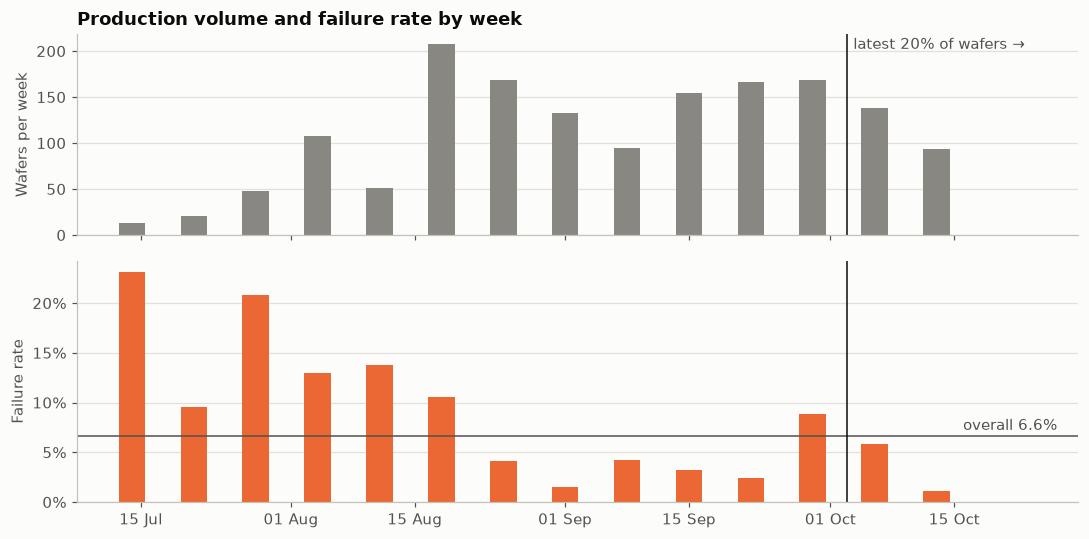

In [5]:
n_fail = int(y.sum())
n_pass = len(y) - n_fail
print(f"Pass: {n_pass} ({n_pass / len(y):.1%}) | Fail: {n_fail} ({n_fail / len(y):.1%}) | imbalance {n_pass / n_fail:.1f} : 1")

fails = pd.Series(y)
monthly = fails.groupby(timestamp.dt.to_period("M")).agg(["size", "mean"])
print("Failure rate by month: " + ", ".join(f"{p.strftime('%b')} {r['mean']:.1%} (n={int(r['size'])})"
                                             for p, r in monthly.iterrows()))

weekly = fails.groupby(timestamp.dt.to_period("W").dt.start_time).agg(["size", "mean"])
n_early = int(round(0.8 * len(y)))          # rows are in time order: the latest 20% start here (Section 8)
time_cut = timestamp.iloc[n_early]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
ax1.bar(weekly.index, weekly["size"], width=3, color=MUTED)
ax1.set_ylabel("Wafers per week")
ax1.set_title("Production volume and failure rate by week")
ax2.bar(weekly.index, weekly["mean"], width=3, color=ORANGE)
ax2.axhline(y.mean(), color=INK_2, linewidth=1)
ax2.set_xlim(right=weekly.index[-1] + pd.Timedelta(days=16))
ax2.annotate(f"overall {y.mean():.1%}", (weekly.index[-1] + pd.Timedelta(days=3), y.mean()), xytext=(0, 4),
             textcoords="offset points", ha="left", color=INK_2)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax2.set_ylabel("Failure rate")
for ax in (ax1, ax2):
    ax.axvline(time_cut, color=INK, linewidth=1)
ax1.annotate("latest 20% of wafers →", (time_cut, ax1.get_ylim()[1]), xytext=(4, -2),
             textcoords="offset points", va="top", color=INK_2)
plt.tight_layout()
plt.show()

**Finding.** Failures are 6.6% of wafers, about 14 passes for every failure. The failure rate also shifts over time: 22% of July's wafers failed, 9% in August, 3% in September and 6% in October.

**Decision.** Accuracy is useless here, because always predicting "pass" already scores 93%. So is *weighted* precision, which is dominated by the pass class (Section 6 shows the baseline scores about 0.87 on it). The metrics are balanced accuracy and cost per wafer. Neither model gets class weights or resampling: the 10:1 cost is handled at the threshold, so the risks must stay honest probabilities. Random CV mixes the high- and low-failure periods, so a time-ordered check tests whether results hold on later wafers.

### 3.2 Missing values, constant sensors and duplicates

Sensors with any missing value: 538 of 590 (435 of them missing in under 1% of wafers)
Sensors missing in more than 40% of wafers: 32. No sensor is missing in between 17.4% and 45.6% of wafers, so any cutoff in that gap drops the same sensors.
Constant sensors: 116 | sensors kept after cleaning: 442 of 590
Duplicate wafers (identical rows): 0 | duplicate sensors among those kept (identical columns): 0
Wafers missing at least one kept reading: 589 (38%). Their failure rate is 6.3%, vs 6.9% for complete wafers.


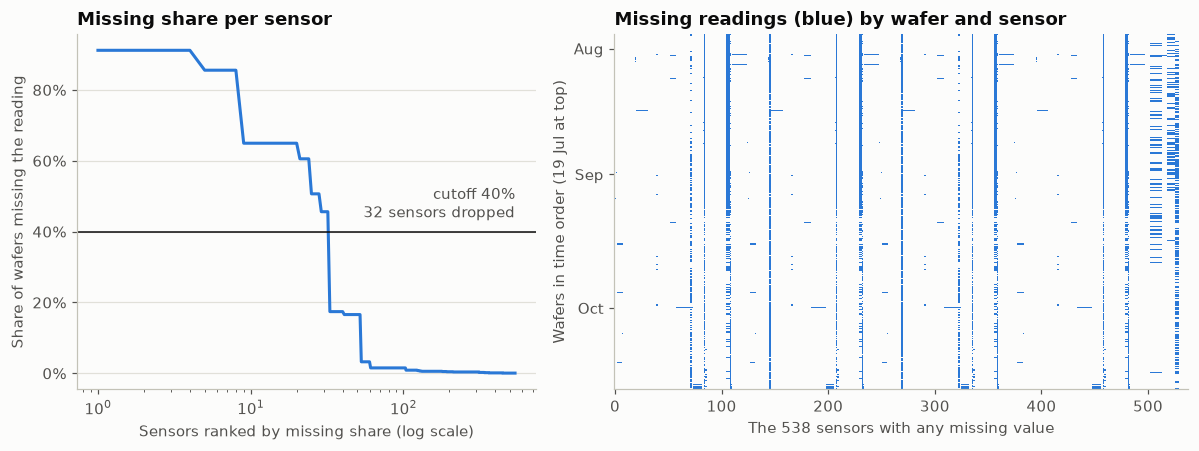

In [6]:
missing_share = X_raw.isna().mean()
high_missing = missing_share > MAX_MISSING
constant = ~(X_raw.max() > X_raw.min())          # a single value across all wafers
kept = ~(high_missing | constant)

below, above = missing_share[~high_missing].max(), missing_share[high_missing].min()
print(f"Sensors with any missing value: {(missing_share > 0).sum()} of {X_raw.shape[1]} "
      f"({(missing_share.between(0, 0.01, inclusive='right')).sum()} of them missing in under 1% of wafers)")
print(f"Sensors missing in more than {MAX_MISSING:.0%} of wafers: {high_missing.sum()}. No sensor is missing in between "
      f"{below:.1%} and {above:.1%} of wafers, so any cutoff in that gap drops the same sensors.")
print(f"Constant sensors: {constant.sum()} | sensors kept after cleaning: {kept.sum()} of {X_raw.shape[1]}")
print(f"Duplicate wafers (identical rows): {X_raw.duplicated().sum()} | "
      f"duplicate sensors among those kept (identical columns): {X_raw.loc[:, kept].T.duplicated().sum()}")

has_gap = X_raw.loc[:, kept].isna().any(axis=1).to_numpy()
print(f"Wafers missing at least one kept reading: {has_gap.sum()} ({has_gap.mean():.0%}). "
      f"Their failure rate is {y[has_gap].mean():.1%}, vs {y[~has_gap].mean():.1%} for complete wafers.")

fig, (axa, axb) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ranked = missing_share[missing_share > 0].sort_values(ascending=False).to_numpy()
axa.plot(np.arange(1, len(ranked) + 1), ranked, color=BLUE)
axa.axhline(MAX_MISSING, color=INK, linewidth=1)
axa.annotate(f"cutoff {MAX_MISSING:.0%}\n{high_missing.sum()} sensors dropped", (len(ranked), MAX_MISSING),
             xytext=(0, 6), textcoords="offset points", ha="right", va="bottom", color=INK_2)
axa.set_xscale("log")
axa.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axa.set_xlabel("Sensors ranked by missing share (log scale)")
axa.set_ylabel("Share of wafers missing the reading")
axa.set_title("Missing share per sensor")

cols = missing_share.index[missing_share > 0]
axb.imshow(X_raw[cols].isna().to_numpy(), aspect="auto", interpolation="nearest",
           cmap=ListedColormap([SURFACE, BLUE]))
month_rows = pd.Series(np.arange(len(y))).groupby(timestamp.dt.to_period("M")).first().iloc[1:]
axb.set_yticks(month_rows.to_numpy(), [p.strftime("%b") for p in month_rows.index])
axb.set_xlabel(f"The {len(cols)} sensors with any missing value")
axb.set_ylabel("Wafers in time order (19 Jul at top)")
axb.set_title("Missing readings (blue) by wafer and sensor")
axb.grid(False)
plt.tight_layout()
plt.show()

**Finding.** Most gaps are small: 435 sensors are missing in under 1% of wafers. 32 sensors are missing in more than 40% of wafers. No sensor falls between 17.4% and 45.6% missing, so the exact cutoff doesn't matter. 116 sensors are constant, and there are no duplicate wafers or duplicate sensors. In the map, gaps often hit a group of sensors on the same wafer (the horizontal streaks). Wafers with a gap fail at about the usual rate (6.3% vs 6.9%).

**Decision (both models).** Drop the constant and mostly-missing sensors once, before modeling, leaving 442. This step uses no labels, and because of the clear gap between 17% and 46% missing, every training fold would drop the same sensors anyway. Fill the remaining gaps with training-fold medians inside each model's pipeline.

### 3.3 Scales, skew and outliers

Sensor standard deviations span 7.8 orders of magnitude (1.0e-04 to 6,550).
Strongly skewed sensors (|skewness| > 2): 247 of 442.
Readings more than 3 SD from their sensor's mean: 0.88% of all readings, spread over 1268 of 1567 wafers.
Sensors with a reading beyond 6 SD: 299; the most extreme reading is 40 SD from its sensor's mean.


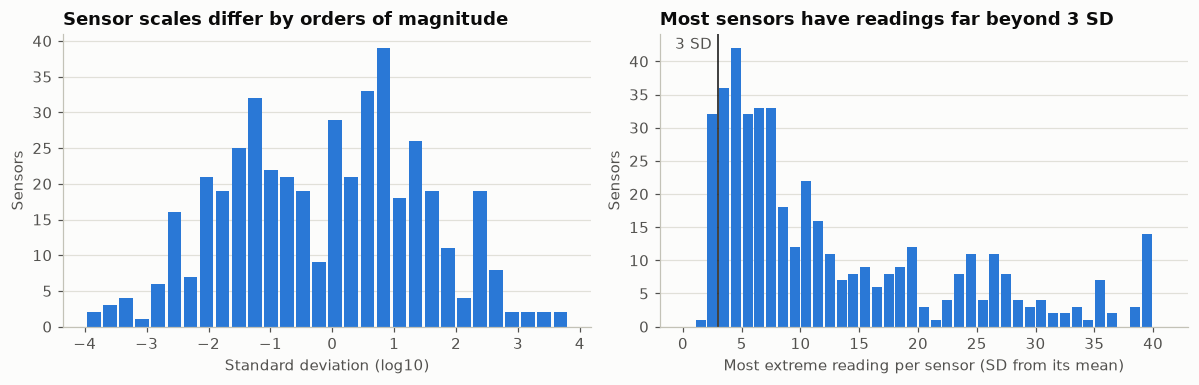

In [7]:
X_kept = X_raw.loc[:, kept]
X_filled = X_kept.fillna(X_kept.median())        # description only: the model imputes inside each CV fold
sd = X_filled.std()
z = (X_filled - X_filled.mean()) / sd
max_abs_z = z.abs().max()

print(f"Sensor standard deviations span {np.log10(sd.max() / sd.min()):.1f} orders of magnitude "
      f"({sd.min():.1e} to {sd.max():,.0f}).")
print(f"Strongly skewed sensors (|skewness| > 2): {(X_filled.skew().abs() > 2).sum()} of {len(sd)}.")
print(f"Readings more than {EXTREME_SD} SD from their sensor's mean: {(z.abs() > EXTREME_SD).to_numpy().mean():.2%} of all readings, "
      f"spread over {(z.abs() > EXTREME_SD).any(axis=1).sum()} of {len(z)} wafers.")
print(f"Sensors with a reading beyond 6 SD: {(max_abs_z > 6).sum()}; "
      f"the most extreme reading is {max_abs_z.max():.0f} SD from its sensor's mean.")

fig, (axa, axb) = plt.subplots(1, 2, figsize=(11, 3.6))
axa.hist(np.log10(sd), bins=30, color=BLUE, rwidth=0.85)
axa.set_xlabel("Standard deviation (log10)")
axa.set_ylabel("Sensors")
axa.set_title("Sensor scales differ by orders of magnitude")
axb.hist(max_abs_z, bins=np.arange(0, np.ceil(max_abs_z.max()) + 2, 1), color=BLUE, rwidth=0.85)
axb.axvline(EXTREME_SD, color=INK, linewidth=1)
axb.annotate(f"{EXTREME_SD} SD", (EXTREME_SD, axb.get_ylim()[1]), xytext=(-4, -2), textcoords="offset points",
             ha="right", va="top", color=INK_2)
axb.set_xlabel("Most extreme reading per sensor (SD from its mean)")
axb.set_ylabel("Sensors")
axb.set_title("Most sensors have readings far beyond 3 SD")
plt.tight_layout()
plt.show()

**Finding.** Sensor scales span almost 8 orders of magnitude, and more than half the sensors are strongly skewed. Extreme readings are common: 1,268 of the 1,567 wafers have at least one reading beyond 3 SD, 299 sensors have a reading beyond 6 SD, and the most extreme reading is 40 SD from its mean.

**Decision.**
- **Logistic regression** adds up weighted readings, so a 40 SD reading can dominate a wafer's score and make the model overconfident. The earlier notebook fixed this by standardizing and clipping at ±3 SD, but the ±3 was picked after seeing results. Here a **quantile transform** replaces both steps: each reading becomes its rank among the training wafers, mapped onto a normal scale. Scale, skew and outliers are handled at once, with nothing to tune. E2 (standardized only) vs E3 (quantile) tests whether it matters.
- **Random forest:** nothing to do. A split such as "sensor_59 > 2.1" depends only on the order of the readings, so scaling or transforming changes nothing, and an extreme reading just lands on one side of a split.

### 3.4 Redundancy between sensors

Sensor pairs with |r| > 0.9: 345 (127 of them above 0.99)
Sensors with at least one near-twin (|r| > 0.9): 303 of 442
Principal components needed for 90% / 95% of the variance: 128 / 161 of 442


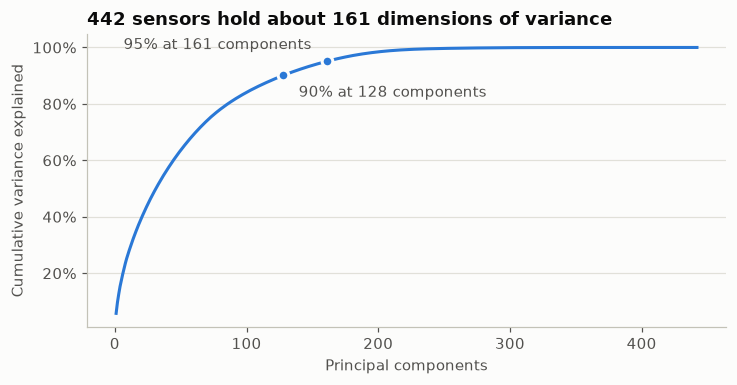

In [8]:
corr = np.corrcoef(z.to_numpy(), rowvar=False)
pair_r = np.abs(corr[np.triu_indices_from(corr, k=1)])
has_twin = ((np.abs(corr) > 0.9).sum(axis=0) - 1) > 0
cum_var = np.cumsum(PCA().fit(z.to_numpy()).explained_variance_ratio_)
n90, n95 = np.searchsorted(cum_var, [0.90, 0.95]) + 1

print(f"Sensor pairs with |r| > 0.9: {(pair_r > 0.9).sum()} ({(pair_r > 0.99).sum()} of them above 0.99)")
print(f"Sensors with at least one near-twin (|r| > 0.9): {has_twin.sum()} of {len(has_twin)}")
print(f"Principal components needed for 90% / 95% of the variance: {n90} / {n95} of {len(cum_var)}")

fig, ax = plt.subplots(figsize=(6.8, 3.6))
ax.plot(np.arange(1, len(cum_var) + 1), cum_var, color=BLUE)
for k, frac, offset, align in ((n90, 0.90, (10, -14), "left"), (n95, 0.95, (-10, 8), "right")):
    ax.plot(k, cum_var[k - 1], "o", color=BLUE, markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{frac:.0%} at {k} components", (k, cum_var[k - 1]), xytext=offset,
                textcoords="offset points", ha=align, color=INK_2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Principal components")
ax.set_ylabel("Cumulative variance explained")
ax.set_title(f"{len(cum_var)} sensors hold about {n95} dimensions of variance")
plt.tight_layout()
plt.show()

**Finding.** Many sensors are near-copies of each other: 303 of the 442 have a partner with |r| > 0.9, and 161 principal components carry 95% of the variance.

**Decision.**
- **Logistic regression:** L2 regularization, which shares weight across near-copies instead of picking one at random, and keeps 442 features from overfitting 104 failures. C is tuned by inner CV.
- **Random forest:** no change needed; each split samples a subset of sensors, so near-copies take turns.
- **Both:** read single-sensor importance with care, because a near-copy can stand in for any sensor.

### 3.5 How much signal single sensors carry

Single-sensor AUC, real labels:     median 0.524, best 0.692; 12 sensors above 0.60
Single-sensor AUC, shuffled labels: median 0.520, best 0.589; 0 sensors above 0.60


,AUC,Spearman correlation with time
sensor_60,0.692,-0.44
sensor_104,0.668,-0.52
sensor_511,0.636,-0.41
sensor_478,0.621,-0.22
sensor_206,0.619,-0.21
sensor_130,0.619,-0.31
sensor_29,0.616,0.59
sensor_34,0.611,-0.15


Time order alone separates fail from pass with AUC 0.636: early wafers fail more often.


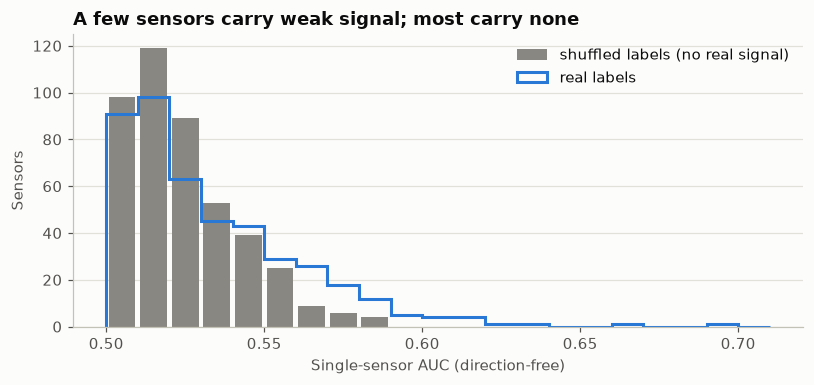

In [9]:
def direction_free_auc(labels, frame):
    auc = frame.apply(lambda col: roc_auc_score(labels, col))
    return np.maximum(auc, 1 - auc)      # 0.5 = no signal, 1.0 = perfect separation

auc_real = direction_free_auc(y, X_filled)
auc_null = direction_free_auc(np.random.default_rng(RANDOM_SEED).permutation(y), X_filled)
print(f"Single-sensor AUC, real labels:     median {auc_real.median():.3f}, best {auc_real.max():.3f}; "
      f"{(auc_real > 0.6).sum()} sensors above 0.60")
print(f"Single-sensor AUC, shuffled labels: median {auc_null.median():.3f}, best {auc_null.max():.3f}; "
      f"{(auc_null > 0.6).sum()} sensors above 0.60")

time_rank = pd.Series(np.arange(len(y)), index=X_filled.index)
top = auc_real.sort_values(ascending=False).head(8)
display(pd.DataFrame({"AUC": top.round(3),
                      "Spearman correlation with time": [round(X_filled[s].corr(time_rank, method="spearman"), 2)
                                                         for s in top.index]}))
print(f"Time order alone separates fail from pass with AUC {roc_auc_score(y, -time_rank):.3f}: early wafers fail more often.")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.linspace(0.5, 0.71, 22)
ax.hist(auc_null, bins=bins, color=MUTED, rwidth=0.85, label="shuffled labels (no real signal)")
ax.hist(auc_real, bins=bins, histtype="step", color=BLUE, linewidth=2, label="real labels")
ax.set_xlabel("Single-sensor AUC (direction-free)")
ax.set_ylabel("Sensors")
ax.set_title("A few sensors carry weak signal; most carry none")
ax.legend()
plt.tight_layout()
plt.show()

**Finding.** The signal is weak and concentrated in a few sensors. The typical sensor separates fail from pass no better than chance (median AUC 0.524, vs 0.520 with shuffled labels). Twelve sensors exceed 0.60, which never happens with shuffled labels, and the best reaches 0.692. Several of the strongest sensors also drift over time (Spearman ρ between −0.52 and +0.59), and time order alone reaches AUC 0.636. Part of what these sensors say about failure may simply be *when* a wafer was made.

**Decision.** Expect modest performance, an AUC near 0.7 rather than 0.9. Keep all sensors and let each model weigh them; hand-picking sensors on all wafers would leak labels. With only 104 failures, fully grown trees can memorize individual failures, so the forest's leaf size is tuned. The time-ordered check matters for both models.

### 3.6 EDA summary: finding → decision → experiment

| Finding | Decision for the starting models | Experiment it motivates |
|---|---|---|
| 6.6% failures; rate falls from 22% (Jul) to 3% (Sep) | Balanced accuracy and cost per wafer; no class weights | Time-ordered check for every experiment; **E8** removes slow drift |
| 32 sensors >40% missing, 116 constant | Dropped once before modeling (442 remain) | |
| Small remaining gaps | Median imputation inside each pipeline | E9 uses the gradient booster's native handling of gaps |
| Scales over 8 orders of magnitude; heavy skew; readings up to 40 SD | Quantile transform for logistic regression (E3 vs E2); nothing for trees | |
| 303 sensors with a near-twin | L2 penalty, C tuned by inner CV | **E5c** tests an L1 penalty, which picks one sensor from a group of copies |
| Weak signal in about a dozen sensors among 442; 104 failures | Tune leaf size; calibrate risks | **E5** keeps only the top-k sensors; **E6** lets each split see more sensors; **E9** shallow boosted trees |
| Linear and tree models catch different failures (10.2 of the earlier run) | Compare both | **E7** averages them |

## 4. The experiment framework
Cleaning happened once in 3.2. Everything else that learns from data is fitted on each training fold only. All code that is shared by the experiments lives in this section, so each experiment in Section 5 is only its own few lines.

**An experiment** is a `fit(X_train, y_train)` function, a `risk(model, X_new)` function and the data frame it sees. `register()` adds it to a registry, and `run_experiment()` then:
1. fits it on each of the 25 outer training folds and stores the held-out risks (`run_cv`);
2. fits it once on the earliest 80% of wafers and stores the risks for the latest 20% (`run_late`);
3. caches both to disk, so reruns are instant.

The loop stores risks only. Thresholds and metrics are applied afterwards, which is why the same stored risks serve the main table, the threshold-0.5 comparison and the calibration plots.

### 4.1 Models and their fit functions
`fit_logreg` and `fit_forest` are unchanged from the earlier notebook, so E1–E4 reproduce its numbers.

In [10]:
X = X_raw.loc[:, kept]                      # the 442 sensors kept in 3.2 (constant and mostly-missing ones dropped)
splits = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_SEED).split(X, y))
early, late = np.arange(n_early), np.arange(n_early, len(y))      # time-ordered check: first 80% -> last 20% (3.1)
print(f"Modeling data: {X.shape[0]} wafers x {X.shape[1]} sensors, {y.sum()} failures | {len(splits)} outer folds")


def fit_baseline(X_train, y_train):
    return {"rate": y_train.mean()}


def baseline_risk(model, X_new):
    return np.full(len(X_new), model["rate"])


def fit_logreg(X_train, y_train, transform):
    """Median-fill gaps and put every sensor on a common scale, then L2 logistic regression with C tuned on log-loss.
    transform: "standard" (E2) or "quantile" (E3). Returns the fitted preprocessing and the C search."""
    if transform == "quantile":
        scale = QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=RANDOM_SEED)
    else:
        scale = StandardScaler()
    prep = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), scale).fit(X_train)
    search = GridSearchCV(LogisticRegression(max_iter=5000), {"C": C_GRID}, scoring="neg_log_loss", n_jobs=-1,
                          cv=StratifiedKFold(N_SPLITS, shuffle=True, random_state=RANDOM_SEED), return_train_score=True)
    search.fit(prep.transform(X_train), y_train)
    return {"prep": prep, "search": search}


def logreg_risk(model, X_new):
    """Predicted risk of failure."""
    return model["search"].predict_proba(model["prep"].transform(X_new))[:, 1]


def fit_forest(X_train, y_train):
    """Try each leaf size; keep the forest whose calibrated out-of-bag risks have the lowest log-loss.
    Returns a dict with the fitted forest, its Platt calibrator, the chosen leaf size and the loss per leaf size."""
    best, curve = None, {}
    for leaf in LEAF_SIZES:
        rf = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True),
                           RandomForestClassifier(n_estimators=N_TREES, min_samples_leaf=leaf, oob_score=True,
                                                  n_jobs=-1, random_state=RANDOM_SEED))
        rf.fit(X_train, y_train)
        oob = rf[-1].oob_decision_function_[:, [1]]           # each wafer's vote share from trees that never saw it
        platt = LogisticRegression(C=1e6, max_iter=1000).fit(oob, y_train)     # vote share -> probability
        oob_loss = log_loss(y_train, platt.predict_proba(oob)[:, 1])
        train_loss = log_loss(y_train, platt.predict_proba(rf.predict_proba(X_train)[:, [1]])[:, 1])
        curve[leaf] = {"train": train_loss, "out-of-bag": oob_loss}
        if best is None or oob_loss < best["loss"]:
            best = {"rf": rf, "platt": platt, "leaf": leaf, "loss": oob_loss}
    best["curve"] = curve
    return best


def forest_risk(forest, X_new, calibrated=True):
    """Calibrated risk of failure, or the raw vote share if calibrated=False."""
    raw = forest["rf"].predict_proba(X_new)[:, [1]]
    return forest["platt"].predict_proba(raw)[:, 1] if calibrated else raw[:, 0]

Modeling data: 1567 wafers x 442 sensors, 104 failures | 25 outer folds


### 4.2 Metrics
One function computes every metric from a vector of risks, so every experiment is scored identically.

In [11]:
def decision_metrics(y_true, risk, threshold=THRESHOLD, cost_fn=COST_FN, cost_fp=COST_FP):
    flagged = (risk >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, flagged, labels=[0, 1]).ravel()
    return {"balanced_accuracy": balanced_accuracy_score(y_true, flagged),
            "recall": tp / (tp + fn),
            "specificity": tn / (tn + fp),
            "precision": tp / (tp + fp) if tp + fp else 0.0,
            "flag_rate": (tp + fp) / len(y_true),
            "cost_per_wafer": (cost_fn * fn + cost_fp * fp) / len(y_true)}


def ranking_metrics(y_true, risk):
    return {"roc_auc": roc_auc_score(y_true, risk), "pr_auc": average_precision_score(y_true, risk)}


def probability_metrics(y_true, risk):
    risk = np.clip(risk, 1e-6, 1 - 1e-6)
    return {"log_loss": log_loss(y_true, risk, labels=[0, 1])}


def all_metrics(y_true, risk, threshold=THRESHOLD):
    return {**decision_metrics(y_true, risk, threshold), **ranking_metrics(y_true, risk), **probability_metrics(y_true, risk)}


LABELS = {"cost_per_wafer": "Cost / wafer", "balanced_accuracy": "Balanced acc.", "recall": "Recall (fail)",
          "specificity": "Specificity", "precision": "Precision (fail)", "flag_rate": "Flag rate",
          "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "log_loss": "Log-loss"}

### 4.3 Registry and runner

In [12]:
# ---- The experiment registry ----------------------------------------------------------------------------------
# An experiment is a name, a data frame, a fit(X_train, y_train) -> model function, a risk(model, X_new) -> risks
# function, and a `parent` it is judged against. The same `splits` and the same metrics are applied to every one.
EXPERIMENTS = {}
risk, late_risk, fold_diag, fit_seconds = {}, {}, {}, {}      # filled by run_cv / run_late; keyed by experiment id


def register(eid, name, fit, predict, data=None, parent=None, diag=None, variants=None, group="Improvements"):
    """data: frame the experiment sees (default X). diag(model) -> small dict kept per fold (chosen settings, importances).
    variants: {suffix: predict_fn} extra risks from the same fit, stored as risk["<eid> <suffix>"] (not separate experiments)."""
    EXPERIMENTS[eid] = {"name": name, "fit": fit, "predict": predict, "data": X if data is None else data,
                        "parent": parent, "diag": diag, "variants": variants or {}, "group": group}


def _cache(kind, eid):
    return CACHE_DIR / f"{kind}_{eid.replace(' ', '_')}.pkl"


def run_cv(eid, force=None):
    """Fit one experiment on the 25 outer training folds and store the held-out risks. Cached on disk per experiment."""
    exp, force = EXPERIMENTS[eid], FORCE if force is None else force
    path = _cache("cv", eid)
    if path.exists() and not force:
        saved = pickle.loads(path.read_bytes())
        risk.update(saved["risk"]); fold_diag[eid] = saved["diag"]; fit_seconds[eid] = saved["seconds"]
        print(f"{eid} {exp['name']}: loaded from cache ({saved['seconds'] / len(splits):.1f}s per fold when fitted)")
        return
    keys = [eid] + [f"{eid} {v}" for v in exp["variants"]]
    out = {k: np.full((N_REPEATS, len(y)), np.nan) for k in keys}
    diags, start = [], time.time()
    for i, (train, test) in enumerate(splits):
        rep = i // N_SPLITS
        model = exp["fit"](exp["data"].iloc[train], y[train])
        out[eid][rep, test] = exp["predict"](model, exp["data"].iloc[test])
        for v, fn in exp["variants"].items():
            out[f"{eid} {v}"][rep, test] = fn(model, exp["data"].iloc[test])
        diags.append(exp["diag"](model) if exp["diag"] else {})
        if (i + 1) % N_SPLITS == 0:
            print(f"{eid} repeat {rep + 1} of {N_REPEATS} done, {time.time() - start:.0f}s so far")
    assert all(not np.isnan(r).any() for r in out.values())
    seconds = time.time() - start
    risk.update(out); fold_diag[eid] = diags; fit_seconds[eid] = seconds
    CACHE_DIR.mkdir(exist_ok=True)
    path.write_bytes(pickle.dumps({"risk": out, "diag": diags, "seconds": seconds}))
    print(f"{eid} {exp['name']}: {seconds:.0f}s")


def run_late(eid, force=None):
    """Train-early, test-late check for one experiment: one fit on the first 80% of wafers, risks for the last 20%."""
    exp, force = EXPERIMENTS[eid], FORCE if force is None else force
    path = _cache("late", eid)
    if path.exists() and not force:
        late_risk[eid] = pickle.loads(path.read_bytes())
        return
    model = exp["fit"](exp["data"].iloc[early], y[early])
    late_risk[eid] = exp["predict"](model, exp["data"].iloc[late])
    CACHE_DIR.mkdir(exist_ok=True)
    path.write_bytes(pickle.dumps(late_risk[eid]))


def run_experiment(eid):
    run_cv(eid)
    run_late(eid)


def register_ensemble(eid, name, parts, parent=None):
    """Average of the calibrated risks of other experiments. Needs no refitting: each part's held-out risk for a wafer
    came from a model that never saw it, so their mean is also an honest held-out risk."""
    for p in parts:
        assert p in risk and p in late_risk, f"run {p} first"
    EXPERIMENTS[eid] = {"name": name, "parts": parts, "parent": parent, "group": "Improvements", "diag": None,
                        "variants": {}}
    risk[eid] = np.mean([risk[p] for p in parts], axis=0)
    late_risk[eid] = np.mean([late_risk[p] for p in parts], axis=0)
    fit_seconds[eid] = sum(fit_seconds[p] for p in parts)
    fold_diag[eid] = []

### 4.4 Scoreboard functions
The `verdict` function encodes the decision rule from the top of the notebook, and `pick_champion` the selection rule.

In [13]:
# ---- The scoreboard: one table, one plot, the same for every experiment ---------------------------------------
def main_ids():
    return [e for e in EXPERIMENTS if e in risk]


def fold_results(keys, threshold=THRESHOLD):
    """One row per risk key (an experiment id or an '<id> variant') and outer fold, with every metric."""
    rows = []
    for key in keys:
        for i, (_, test) in enumerate(splits):
            rows.append({"key": key, "fold": i, **all_metrics(y[test], risk[key][i // N_SPLITS, test], threshold)})
    return pd.DataFrame(rows)


def late_metrics(key):
    r = late_risk[key]
    return {**all_metrics(y[late], r), "mean_risk": r.mean()}


def build_scoreboard():
    ids = main_ids()
    res = fold_results(ids)
    per_fold = {m: res.pivot(index="fold", columns="key", values=m)[ids] for m in LABELS}
    cost = per_fold["cost_per_wafer"]
    board = pd.DataFrame(index=ids)
    board["name"] = [EXPERIMENTS[e]["name"] for e in ids]
    for m, label in LABELS.items():
        board[label] = per_fold[m].mean()
    board["Cost sd"] = cost.std()
    board["Folds cheaper than E1"] = [(cost[e] < cost["E1"]).sum() for e in ids]
    parent = [EXPERIMENTS[e]["parent"] for e in ids]
    board["parent"] = [p or "" for p in parent]
    board["Folds cheaper than parent"] = [(cost[e] < cost[p]).sum() if p else np.nan for e, p in zip(ids, parent)]
    board["Cost change vs parent"] = [cost[e].mean() - cost[p].mean() if p else np.nan for e, p in zip(ids, parent)]
    # Mean paired change divided by its standard error. Rough guide only: the 25 folds share training wafers, so the
    # true standard error is larger and |Change / SE| below about 2 should be read as "within noise".
    board["Change / SE"] = [(cost[e] - cost[p]).mean() / ((cost[e] - cost[p]).std() / np.sqrt(len(splits))) if p else np.nan
                            for e, p in zip(ids, parent)]
    late_tab = pd.DataFrame({e: late_metrics(e) for e in ids if e in late_risk}).T
    board["Late cost"] = late_tab["cost_per_wafer"]
    board["Late ROC-AUC"] = late_tab["roc_auc"]
    board["Late bal. acc."] = late_tab["balanced_accuracy"]
    board["Late mean risk"] = late_tab["mean_risk"]
    board["Fit s/fold"] = [fit_seconds.get(e, np.nan) / len(splits) for e in ids]
    return board, per_fold


def verdict(row, min_wins=15):
    """The decision rule fixed in advance: keep a change if it lowers mean cost versus its parent AND does so in
    at least `min_wins` of 25 folds; note separately whether it also beats its parent on the late wafers."""
    if not row["parent"]:
        return ""
    if row["Cost change vs parent"] < 0 and row["Folds cheaper than parent"] >= min_wins:
        return "keep"
    return "no clear gain" if row["Cost change vs parent"] < 0 else "reject"


def show_scoreboard(board):
    cols = ["name", "Cost / wafer", "Cost sd", "Balanced acc.", "Recall (fail)", "Precision (fail)", "Flag rate", "ROC-AUC",
            "PR-AUC", "Log-loss", "Folds cheaper than E1", "parent", "Folds cheaper than parent", "Cost change vs parent",
            "Change / SE", "Late cost", "Late ROC-AUC", "Fit s/fold"]
    shown = board.sort_values("Cost / wafer")[cols].copy()
    shown["verdict"] = board.apply(verdict, axis=1)
    fmt = {c: "{:.3f}" for c in shown.columns if shown[c].dtype.kind == "f"}
    fmt.update({"Folds cheaper than parent": "{:.0f}", "Fit s/fold": "{:.1f}", "Cost change vs parent": "{:+.3f}", "Change / SE": "{:+.1f}"})
    styler = (shown.style.format(fmt, na_rep="").highlight_min(subset=["Cost / wafer", "Late cost", "Log-loss"], color="#dbeafe")
                    .highlight_max(subset=["ROC-AUC", "PR-AUC", "Balanced acc.", "Late ROC-AUC"], color="#dbeafe"))
    display(styler)
    return shown


def pick_champion(board):
    """Selection rule: lowest mean CV cost among experiments that also beat the baseline on the late wafers."""
    ok = board[(board["Late cost"] < board.loc["E1", "Late cost"]) | (board.index == "E1")]
    ok = ok.drop(index="E1", errors="ignore")
    return ok["Cost / wafer"].idxmin(), board["Cost / wafer"].drop(index="E1").idxmin()


def plot_cost_by_fold(per_fold, order, champion):
    cost = per_fold["cost_per_wafer"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
    for ax, metric, title in ((axes[0], "cost_per_wafer", "Cost per wafer per fold (lower is better)"),
                              (axes[1], "roc_auc", "ROC-AUC per fold (higher is better)")):
        table = per_fold[metric]
        for k, e in enumerate(order):
            vals = table[e].to_numpy()
            color = ORANGE if e == champion else (MUTED if e == "E1" else BLUE)
            jitter = np.random.default_rng(k).uniform(-0.13, 0.13, len(vals))
            ax.scatter(k + jitter, vals, s=16, color=color, alpha=0.8, edgecolor=SURFACE, linewidth=0.5, zorder=3)
            ax.plot([k - 0.3, k + 0.3], [vals.mean()] * 2, color=INK, linewidth=2, zorder=4)
        ax.set_xticks(range(len(order)), order, rotation=45, ha="right")
        ax.set_title(title)
    plt.tight_layout()
    plt.show()
    print(f"Dots: the {len(splits)} outer folds. Black bars: means. Orange: the champion ({champion}). Grey: the baseline.")

## 5. Experiments
Each experiment has a hypothesis written before it was run, a code cell, and a short reading of the result. The numbers for all of them side by side are in Section 6.

### 5.1 Starting models (E1–E4)
- **E1** majority baseline: always predict "pass" (risk = training failure rate, which is below the 0.091 threshold).
- **E2** L2 logistic regression on standardized sensors; C tuned by inner 5-fold CV on log-loss.
- **E3** the same with a quantile transform (each reading becomes its rank on a normal scale) instead of standardizing. It bounds extreme readings and removes skew with nothing to tune.
- **E4** random forest with 200 trees: median imputer, no scaling (tree splits depend only on order). Leaf size is tuned and the vote share is turned into a probability by a Platt step, both on out-of-bag predictions, which cost no extra fitting.

The risks of E3 and E4 are the reference points for everything that follows.

In [14]:
register("E1", "Majority baseline", fit_baseline, baseline_risk, group="Starting models")
register("E2", "LR, standardized", lambda Xt, yt: fit_logreg(Xt, yt, "standard"), logreg_risk, parent="E1",
         group="Starting models",
         diag=lambda m: {"C": m["search"].best_params_["C"],
                         "curve": (-m["search"].cv_results_["mean_train_score"], -m["search"].cv_results_["mean_test_score"])})
register("E3", "LR, quantile transform", lambda Xt, yt: fit_logreg(Xt, yt, "quantile"), logreg_risk, parent="E2",
         group="Starting models",
         diag=lambda m: {"C": m["search"].best_params_["C"],
                         "curve": (-m["search"].cv_results_["mean_train_score"], -m["search"].cv_results_["mean_test_score"]),
                         "coef": pd.Series(m["search"].best_estimator_.coef_[0], index=X.columns)})
register("E4", "Random forest, calibrated", fit_forest, forest_risk, parent="E3", group="Starting models",
         variants={"raw": lambda m, Xn: forest_risk(m, Xn, calibrated=False)},
         diag=lambda m: {"leaf": m["leaf"], "curve": m["curve"],
                         "importance": pd.Series(m["rf"][-1].feature_importances_, index=X.columns)})

for eid in ("E1", "E2", "E3", "E4"):
    run_experiment(eid)

E1 Majority baseline: loaded from cache (0.0s per fold when fitted)
E2 LR, standardized: loaded from cache (0.6s per fold when fitted)
E3 LR, quantile transform: loaded from cache (1.2s per fold when fitted)
E4 Random forest, calibrated: loaded from cache (4.1s per fold when fitted)


**What the quantile transform does to one sensor.** The sensor with the most extreme reading, before and after. The transform is fitted on all wafers here for illustration only; in the model it is fitted on each training fold.

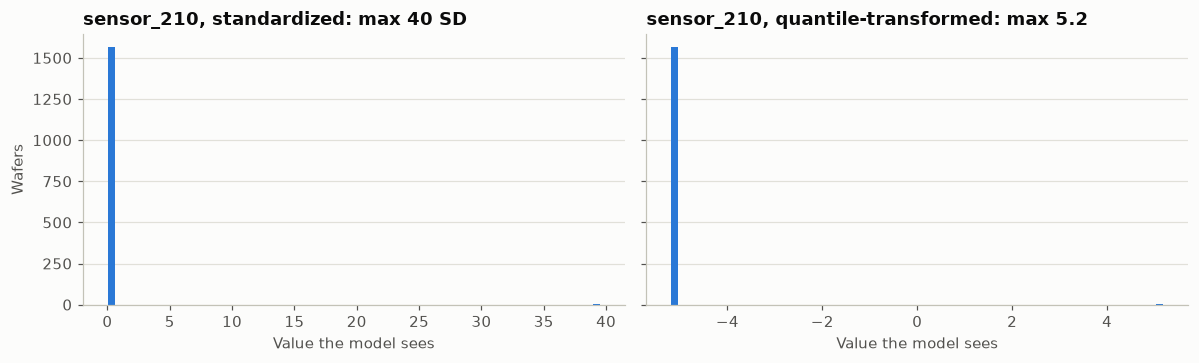

In [15]:
demo = max_abs_z.idxmax()
raw_z = z[demo]
quantile_z = QuantileTransformer(n_quantiles=500, output_distribution="normal").fit_transform(X_filled[[demo]])[:, 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, values, title in ((axes[0], raw_z, f"{demo}, standardized: max {raw_z.abs().max():.0f} SD"),
                          (axes[1], quantile_z, f"{demo}, quantile-transformed: max {np.abs(quantile_z).max():.1f}")):
    ax.hist(values, bins=60, color=BLUE, rwidth=0.85)
    ax.set_title(title)
    ax.set_xlabel("Value the model sees")
axes[0].set_ylabel("Wafers")
plt.tight_layout()
plt.show()

**Result.** E1–E4 reproduce the earlier notebook exactly (cost 0.664 / 0.568 / 0.537 / 0.510), which confirms the refactor changed nothing. Both models beat the baseline in 25 of 25 folds (E3: 24). The quantile transform (E3) beats plain standardizing (E2) in 17 of 25 folds, and the forest (E4) beats E3 in 18 of 25. The fold-to-fold standard deviation of cost is 0.05–0.07, which is larger than most gaps between the models.

### 5.2 E5: feature selection
**Hypothesis.** Only about a dozen of the 442 sensors carry signal (3.5). Fitting weights or splits on the other ~430 adds noise, especially with 104 failures. Keeping only the top-k sensors should help, most for logistic regression.

**Leak-free construction.** Choosing the top-k sensors by their relation to the labels must be done on training wafers only, and the choice of k itself has to be validated.
- **E5a** (logistic regression): `SelectKBest(f_classif)` sits *inside* the inner CV pipeline, so for each inner fold the sensors are chosen on that fold's training part only. k and C are tuned together.
- **E5b** (forest): the same selector in front of the forest. The out-of-bag shortcut E4 uses is no longer honest once labels picked the sensors, so k, leaf size and the Platt calibration come from an inner 5-fold CV instead.
- **E5c** (L1 logistic regression): the penalty itself drives most weights to exactly zero, an embedded form of selection. C is tuned by inner CV.

In [16]:
# E5a: logistic regression on the top-k sensors. The selector sits inside the inner CV pipeline, so k and C are tuned
# together and the selection never sees an inner validation wafer's label.
def fit_logreg_selected(X_train, y_train):
    prep = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True),
                         QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=RANDOM_SEED)).fit(X_train)
    pipe = Pipeline([("select", SelectKBest(f_classif)), ("lr", LogisticRegression(max_iter=5000))])
    search = GridSearchCV(pipe, {"select__k": K_GRID_LR, "lr__C": C_GRID_SEL}, scoring="neg_log_loss", n_jobs=-1,
                          cv=StratifiedKFold(N_SPLITS, shuffle=True, random_state=RANDOM_SEED))
    search.fit(prep.transform(X_train), y_train)
    return {"prep": prep, "search": search}


register("E5a", "LR, top-k sensors", fit_logreg_selected, logreg_risk, parent="E3",
         diag=lambda m: {"k": m["search"].best_params_["select__k"], "C": m["search"].best_params_["lr__C"]})


# E5c: L1 (lasso) logistic regression, which selects sensors by shrinking weights to exactly zero.
def fit_logreg_l1(X_train, y_train):
    prep = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True),
                         QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=RANDOM_SEED)).fit(X_train)
    search = GridSearchCV(LogisticRegression(penalty="l1", solver="liblinear", max_iter=5000), {"C": C_GRID_L1},
                          scoring="neg_log_loss", n_jobs=-1,
                          cv=StratifiedKFold(N_SPLITS, shuffle=True, random_state=RANDOM_SEED))
    search.fit(prep.transform(X_train), y_train)
    return {"prep": prep, "search": search}


register("E5c", "LR, L1 penalty", fit_logreg_l1, logreg_risk, parent="E3",
         diag=lambda m: {"C": m["search"].best_params_["C"],
                         "k": int((m["search"].best_estimator_.coef_[0] != 0).sum())})


# E5b and E9 need calibrated risks from a model whose settings were chosen using labels. The out-of-bag shortcut used by E4
# is no longer honest once the selector has seen the labels, so these use an inner CV: out-of-fold risks for every setting,
# a Platt step fitted on them, and the setting with the lowest calibrated log-loss.
def inner_calibrated(estimator, Xt, yt):
    oof = cross_val_predict(estimator, Xt, yt, method="predict_proba",
                            cv=StratifiedKFold(N_SPLITS, shuffle=True, random_state=RANDOM_SEED))[:, [1]]
    platt = LogisticRegression(C=1e6, max_iter=1000).fit(oof, yt)
    return log_loss(yt, platt.predict_proba(oof)[:, 1]), platt


def fit_search_calibrated(X_train, y_train, make_estimator, grid, impute=True):
    """grid: list of setting dicts. Returns the refitted best estimator, its Platt step and the chosen setting."""
    imputer = SimpleImputer(strategy="median", keep_empty_features=True).fit(X_train) if impute else None
    Xt = imputer.transform(X_train) if impute else X_train
    best = None
    for setting in grid:
        loss, platt = inner_calibrated(make_estimator(setting), Xt, y_train)
        if best is None or loss < best["loss"]:
            best = {"loss": loss, "platt": platt, "setting": setting}
    best["model"] = make_estimator(best["setting"]).fit(Xt, y_train)
    best["imputer"] = imputer
    return best


def calibrated_risk(m, X_new):
    Xt = m["imputer"].transform(X_new) if m["imputer"] is not None else X_new
    return m["platt"].predict_proba(m["model"].predict_proba(Xt)[:, [1]])[:, 1]


def make_selected_forest(s):
    return Pipeline([("select", SelectKBest(f_classif, k=s["k"])),
                     ("rf", RandomForestClassifier(n_estimators=N_TREES, min_samples_leaf=s["leaf"], n_jobs=-1,
                                                   random_state=RANDOM_SEED))])


register("E5b", "Random forest, top-k sensors",
         lambda Xt, yt: fit_search_calibrated(Xt, yt, make_selected_forest,
                                              [{"k": k, "leaf": l} for k in K_GRID_RF for l in LEAF_GRID_TUNED]),
         calibrated_risk, parent="E4", diag=lambda m: dict(m["setting"]))

for eid in ("E5a", "E5b", "E5c"):
    run_experiment(eid)

E5a LR, top-k sensors: loaded from cache (2.3s per fold when fitted)
E5b Random forest, top-k sensors: loaded from cache (9.9s per fold when fitted)
E5c LR, L1 penalty: loaded from cache (2.2s per fold when fitted)


**Result.**
- **E5a (top-k for logistic regression): rejected.** Cost 0.541 vs E3's 0.537, cheaper in only 6 of 25 folds. The inner CV did not settle on a number of sensors: it picked k = 442 (all) in 8 folds and 10, 20, 40 or 80 in the others, so the hypothesis that ~430 noise sensors hurt the linear model was not supported. L2 already shrinks them.
- **E5c (L1 penalty): no clear gain on cost** (0.530, cheaper in 12 of 25 folds, change -0.006), but it is the best linear model on ranking (ROC-AUC 0.704 vs 0.695) and recall (0.498 vs 0.450). It keeps about 72 of 442 sensors.
- **E5b (top-k for the forest): same cost as E4** (0.511 vs 0.510; 15 or 40 sensors chosen, leaf 30 in 24 of 25 folds). Its value shows in the time-ordered check below: late ROC-AUC 0.666 vs E4's 0.549 and late cost 0.540 vs 0.588.

### 5.3 E6: a tuned forest
**Hypothesis.** The default `max_features="sqrt"` lets each split look at only about 21 of 442 sensors. With a dozen useful ones, most splits never see one. Letting each split see 10% or 30% of the sensors should improve the ranking, at the cost of more correlated trees. Leaf size is tuned together with it, by the same calibrated out-of-bag log-loss as E4.

In [17]:
# E6: the forest's max_features (sensors tried per split) and leaf size, both chosen by calibrated out-of-bag log-loss.
def fit_forest_tuned(X_train, y_train):
    imputer = SimpleImputer(strategy="median", keep_empty_features=True).fit(X_train)
    Xt, best, curve = imputer.transform(X_train), None, {}
    for mf in MAX_FEATURES_GRID:
        for leaf in LEAF_GRID_TUNED:
            rf = RandomForestClassifier(n_estimators=N_TREES, max_features=mf, min_samples_leaf=leaf, oob_score=True,
                                        n_jobs=-1, random_state=RANDOM_SEED).fit(Xt, y_train)
            oob = rf.oob_decision_function_[:, [1]]
            platt = LogisticRegression(C=1e6, max_iter=1000).fit(oob, y_train)
            loss = log_loss(y_train, platt.predict_proba(oob)[:, 1])
            curve[(mf, leaf)] = loss
            if best is None or loss < best["loss"]:
                best = {"rf": rf, "platt": platt, "loss": loss, "max_features": mf, "leaf": leaf}
    return {**best, "imputer": imputer, "curve": curve}


def tuned_forest_risk(m, X_new):
    raw = m["rf"].predict_proba(m["imputer"].transform(X_new))[:, [1]]
    return m["platt"].predict_proba(raw)[:, 1]


register("E6", "Random forest, tuned max_features", fit_forest_tuned, tuned_forest_risk, parent="E4",
         diag=lambda m: {"max_features": str(m["max_features"]), "leaf": m["leaf"],
                         "importance": pd.Series(m["rf"].feature_importances_, index=X.columns)})
run_experiment("E6")

E6 Random forest, tuned max_features: loaded from cache (24.4s per fold when fitted)


**Result.** The forest tuned for `max_features` is the best single model on ranking and probability quality: ROC-AUC 0.748 (E4: 0.742) and the lowest held-out log-loss of any single model (0.2226). Larger values won most often: 0.3 in 13 folds, 0.1 in 6 and `sqrt` in 6, which supports the idea that the default hides the useful sensors from many splits. But the cost gain is small (-0.008, cheaper in only 9 of 25 folds), so by the decision rule this is **no clear gain**. Its late-wafer ROC-AUC is 0.539, as low as E4's.

### 5.4 E7: ensemble
**Hypothesis.** The logistic regression and the forest rank wafers differently and catch different failures, so the mean of their calibrated risks should rank better than either. Averaging probabilities (not ranks) keeps the 1/11 threshold meaningful. This needs no new fitting: each model's held-out risk for a wafer came from a fold model that never saw it.
- **E7a** is fixed in advance: E3 + E4.
- **E7b** is the best linear experiment plus the best forest experiment among E3–E6. Because those were picked by CV cost on the same 25 folds, E7b is slightly optimistic; treat its late-wafer result as the fairer test.

In [18]:
# E7a is fixed in advance: the two starting models. E7b averages the best linear and best forest experiment found so far;
# since those were picked by CV cost on these same folds, E7b is slightly optimistic and its late-wafer result is the fairer test.
linear_ids = [e for e in ("E3", "E5a", "E5c") if e in risk]
forest_ids = [e for e in ("E4", "E5b", "E6") if e in risk]
cost_now = {e: np.mean([decision_metrics(y[t], risk[e][i // N_SPLITS, t])["cost_per_wafer"] for i, (_, t) in enumerate(splits)])
            for e in linear_ids + forest_ids}
best_linear, best_forest = min(linear_ids, key=cost_now.get), min(forest_ids, key=cost_now.get)
print(f"Best linear experiment so far: {best_linear}; best forest experiment so far: {best_forest}")

register_ensemble("E7a", "Average of E3 and E4", ["E3", "E4"], parent="E4")
register_ensemble("E7b", f"Average of {best_linear} and {best_forest}", [best_linear, best_forest], parent="E4")

Best linear experiment so far: E5c; best forest experiment so far: E6


**Result.**
- **E7a (E3 + E4, fixed in advance)** costs the same as E4 in random CV (0.511), but it is the best experiment on the late wafers: late cost 0.470 (lowest of all) and late ROC-AUC 0.643 vs the forest's 0.549. Averaging makes the forest's drift-sensitive ranking much more robust.
- **E7b (E5c + E6)** has the lowest CV cost of all (0.490), the lowest log-loss (0.2207) and the highest balanced accuracy (0.667). It is cheaper than E4 in 16 of 25 folds, so it passes the decision rule, but the change (-0.020) is only 1.4 standard errors, so it is **within noise**, and it was picked on the same folds it is scored on.

### 5.5 E8: drift handling
**Hypothesis.** Several of the strongest sensors drift with time (3.5), the failure rate falls from July to September (3.1), and the forest's ranking dropped sharply on the late wafers in the earlier run. Part of what the models learn is *when* a wafer was made. Subtracting each sensor's recent level should remove that, and so help most on the late wafers, possibly at some cost in random CV, where drift is a legitimate (if non-transferable) signal.

**Construction.** Each reading is replaced by its difference from the median of the previous W wafers (W = 200, fixed in advance; W = 100 and 400 are sensitivity checks on the logistic regression). It uses only earlier sensor readings, never labels, so it is available at prediction time. It is computed once on the time-ordered series, which is a label-free step listed in the leakage checklist.

In [19]:
# E8: remove slow drift from each sensor. Every reading becomes its difference from the median of the previous W wafers
# (rows are in time order). This uses only earlier sensor readings and no labels, so it is available at prediction time.
def causal_detrend(frame, window):
    baseline = frame.rolling(window, min_periods=20).median().shift(1)
    return frame - baseline


X_detrended = {w: causal_detrend(X, w) for w in DRIFT_WINDOWS}
drift_before = X.corrwith(pd.Series(np.arange(len(X)), index=X.index), method="spearman").abs()
drift_after = X_detrended[DRIFT_WINDOW].corrwith(pd.Series(np.arange(len(X)), index=X.index), method="spearman").abs()
print(f"Sensors with |Spearman correlation with time| > 0.3: {(drift_before > 0.3).sum()} before, "
      f"{(drift_after > 0.3).sum()} after detrending (W={DRIFT_WINDOW})")

register("E8a", f"LR, quantile, detrended (W={DRIFT_WINDOW})", lambda Xt, yt: fit_logreg(Xt, yt, "quantile"), logreg_risk,
         data=X_detrended[DRIFT_WINDOW], parent="E3", diag=lambda m: {"C": m["search"].best_params_["C"]})
register("E8b", f"Random forest, detrended (W={DRIFT_WINDOW})", fit_forest, forest_risk,
         data=X_detrended[DRIFT_WINDOW], parent="E4", diag=lambda m: {"leaf": m["leaf"]})
for w in DRIFT_WINDOWS:
    if w != DRIFT_WINDOW:
        register(f"E8-W{w}", f"LR, quantile, detrended (W={w})", lambda Xt, yt: fit_logreg(Xt, yt, "quantile"), logreg_risk,
                 data=X_detrended[w], parent="E3", diag=lambda m: {"C": m["search"].best_params_["C"]})

for eid in [e for e in EXPERIMENTS if e.startswith("E8")]:
    run_experiment(eid)

Sensors with |Spearman correlation with time| > 0.3: 46 before, 0 after detrending (W=200)
E8a LR, quantile, detrended (W=200): loaded from cache (1.9s per fold when fitted)
E8b Random forest, detrended (W=200): loaded from cache (4.9s per fold when fitted)
E8-W100 LR, quantile, detrended (W=100): loaded from cache (1.3s per fold when fitted)
E8-W400 LR, quantile, detrended (W=400): loaded from cache (1.3s per fold when fitted)


**Result: rejected, and clearly.** Detrending removed the time-related drift (sensors with |Spearman| above 0.3 with time went from 46 to 0), but every variant got *worse*: logistic regression cost rose from 0.537 to 0.591 (W = 200), and the forest's from 0.510 to 0.550. The window check is monotonic: W = 100 → 0.627, 200 → 0.591, 400 → 0.580, so shorter windows destroy more signal. It also did not help on the late wafers (forest late ROC-AUC 0.521 vs 0.549; logistic regression 0.631 vs 0.675). The hypothesis was wrong: the slowly varying part of the strongest sensors is useful for predicting failure (a sensor level that stays high can be the fault itself), and subtracting a recent median removes it.

### 5.6 E9: gradient boosting
**Hypothesis.** Boosted shallow trees can combine weak sparse signals better than a forest of deep trees. With only 104 failures it can overfit, so the model is small (depth 2–3, learning rate 0.03, early stopping, L2 penalty, 30% of sensors per split), depth and leaf size are chosen by an inner CV, and the output is Platt-calibrated on the inner out-of-fold scores, like E5b.

In [20]:
# E9: shallow gradient-boosted trees, calibrated like E5b with an inner CV. HistGradientBoosting handles gaps natively.
def make_hgb(s):
    return HistGradientBoostingClassifier(learning_rate=0.03, max_iter=300, max_depth=s["depth"], min_samples_leaf=s["leaf"],
                                          l2_regularization=1.0, max_features=0.3, early_stopping=True,
                                          validation_fraction=0.15, n_iter_no_change=20, random_state=RANDOM_SEED)


register("E9", "Gradient boosting, calibrated",
         lambda Xt, yt: fit_search_calibrated(Xt, yt, make_hgb, [{"depth": d, "leaf": l} for d in HGB_DEPTHS for l in HGB_LEAVES],
                                              impute=False),
         calibrated_risk, parent="E4", diag=lambda m: dict(m["setting"]))
run_experiment("E9")

E9 Gradient boosting, calibrated: loaded from cache (10.4s per fold when fitted)


**Result: rejected.** Shallow boosted trees cost 0.538 (E4: 0.510), with ROC-AUC 0.723 and a low recall of 0.354 (E4: 0.442). With 104 failures the booster has too little to learn from; depth 2 and 3 were chosen about equally often. Its late-wafer numbers (cost 0.521, ROC-AUC 0.628) are better than E4's but no better than the logistic regression's (0.482, 0.675), so it is not a convincing exception.

## 6. Scoreboard
Every experiment on the same 25 outer folds. Cost per wafer is in false-alarm units: always passing costs 10 for every failure, so the baseline pays about 0.66 per wafer. Blue cells mark the best value in a column. **Folds cheaper than parent** counts the folds (of 25) in which the experiment costs less than the experiment it was derived from, and `verdict` applies the decision rule. **Change / SE** is the mean paired cost change divided by its standard error; the folds share training wafers, so the true error is larger, and values between -2 and +2 should be read as noise. The *Late* columns are the one-shot train-early, test-late check (313 wafers, 17 failures, so each failure moves recall by about 6 points: rough).

### 6.1 Leaderboard

,name,Cost / wafer,Cost sd,Balanced acc.,Recall (fail),Precision (fail),Flag rate,ROC-AUC,PR-AUC,Log-loss,Folds cheaper than E1,parent,Folds cheaper than parent,Cost change vs parent,Change / SE,Late cost,Late ROC-AUC,Fit s/fold,verdict
E7b,Average of E5c and E6,0.490,0.072,0.667,0.510,0.171,0.198,0.739,0.224,0.221,25,E4,16,-0.020,-1.4,0.530,0.621,26.5,keep
E6,"Random forest, tuned max_features",0.503,0.050,0.653,0.459,0.175,0.175,0.748,0.206,0.223,25,E4,9,-0.008,-0.7,0.556,0.539,24.4,no clear gain
E4,"Random forest, calibrated",0.510,0.068,0.646,0.442,0.175,0.170,0.742,0.189,0.225,25,E3,18,-0.026,-2.0,0.588,0.549,4.1,keep
E7a,Average of E3 and E4,0.511,0.073,0.648,0.454,0.172,0.178,0.735,0.195,0.224,24,E4,12,+0.000,+0.0,0.470,0.643,5.3,reject
E5b,"Random forest, top-k sensors",0.511,0.059,0.651,0.479,0.163,0.197,0.736,0.173,0.227,25,E4,11,+0.000,+0.0,0.540,0.666,9.9,reject
E5c,"LR, L1 penalty",0.530,0.074,0.643,0.498,0.144,0.230,0.704,0.209,0.230,25,E3,12,-0.006,-0.5,0.562,0.643,2.2,no clear gain
E3,"LR, quantile transform",0.537,0.065,0.633,0.450,0.149,0.201,0.695,0.180,0.229,24,E2,17,-0.031,-2.4,0.482,0.675,1.2,keep
E9,"Gradient boosting, calibrated",0.538,0.065,0.618,0.354,0.178,0.133,0.723,0.186,0.231,25,E4,9,+0.028,+2.2,0.521,0.628,10.4,reject
E5a,"LR, top-k sensors",0.541,0.065,0.631,0.450,0.147,0.206,0.689,0.166,0.232,25,E3,6,+0.005,+0.5,0.569,0.569,2.3,reject
E8b,"Random forest, detrended (W=200)",0.550,0.049,0.612,0.356,0.163,0.146,0.707,0.172,0.230,25,E4,7,+0.040,+3.4,0.613,0.521,4.9,reject



Lowest mean CV cost: E7b (Average of E5c and E6).
Champion by the selection rule (lowest CV cost among experiments that also beat the baseline on late wafers): E7b (Average of E5c and E6).


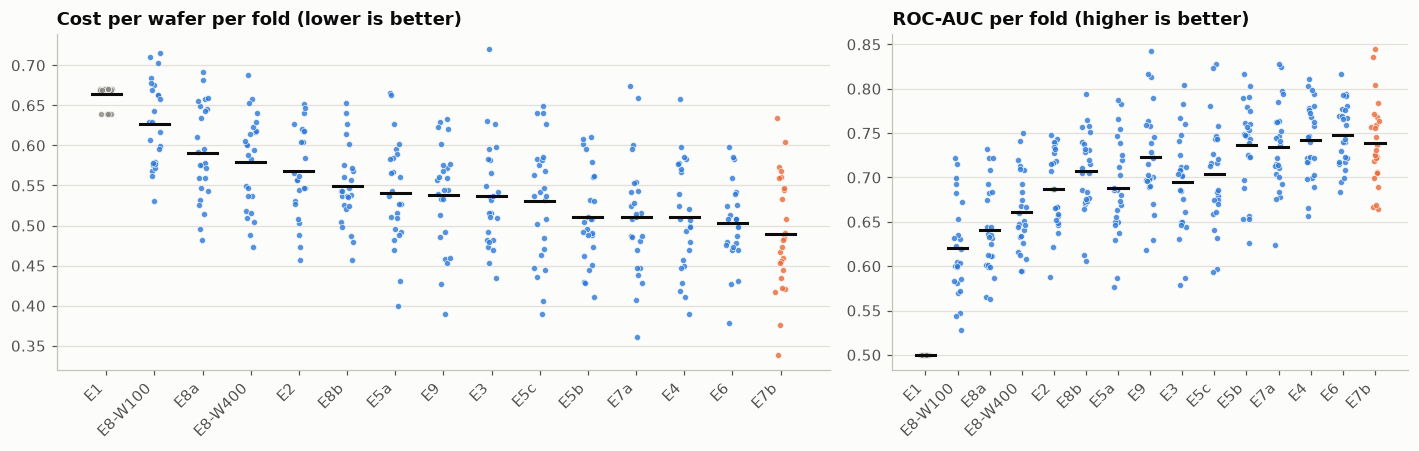

Dots: the 25 outer folds. Black bars: means. Orange: the champion (E7b). Grey: the baseline.


In [21]:
board, per_fold = build_scoreboard()
champion, best_cv = pick_champion(board)
shown = show_scoreboard(board)
print(f"\nLowest mean CV cost: {best_cv} ({board.loc[best_cv, 'name']}).")
print(f"Champion by the selection rule (lowest CV cost among experiments that also beat the baseline on late wafers): "
      f"{champion} ({board.loc[champion, 'name']}).")
RESULTS_DIR.mkdir(exist_ok=True)
board.assign(verdict=board.apply(verdict, axis=1)).to_csv(RESULTS_DIR / "scoreboard.csv")
plot_cost_by_fold(per_fold, list(board.sort_values("Cost / wafer", ascending=False).index), champion)

**Reading the scoreboard.**
- **No experiment is clearly better than E4 or E3.** The best single changes move cost by less than 0.03, while a fold's cost has a standard deviation of 0.05–0.07 and every |Change / SE| for the improvement experiments (E5–E7) is below 2 (and that SE is understated). Treat the differences among E3, E4, E5b, E6 and E7a as ties.
- **What helped a little:** a tuned forest (E6, best ranking and log-loss among single models), an L1 logistic regression (E5c, best linear ranking and recall), and above all averaging a linear model with a forest (E7). The two families flag different failures (7.5), which is what averaging exploits.
- **What clearly hurt:** detrending (E8) and the boosted trees (E9). Sensor selection (E5a) did nothing for the linear model.
- **The champion by the pre-set rule is E7b**, with cost 0.490 vs the baseline's 0.664 and E4's 0.510. It was selected on the same folds it is scored on, so expect its true advantage to be smaller than what the table shows. If one pre-registered choice is wanted, **E7a** is the cleaner pick: no selection, the same CV cost as the best single model, and the best late-wafer behavior.
- **Ceiling:** every reasonable model lands at cost 0.49–0.54 and ROC-AUC 0.69–0.75, in line with the weak single-sensor signal found in 3.5.

### 6.2 Time-ordered check, in detail
Each experiment trained once on the earliest 80% of wafers (with its own tuning and calibration done on those wafers) and scored on the latest 20%. Compare *mean risk* with the actual late failure rate to see whether the risk scale transfers.

In [22]:
print(f"Train (early): {timestamp.iloc[0]:%d %b} to {timestamp.iloc[n_early - 1]:%d %b}, {len(early)} wafers, "
      f"{y[early].sum()} failures ({y[early].mean():.1%})")
print(f"Test (late):   {timestamp.iloc[n_early]:%d %b} to {timestamp.iloc[-1]:%d %b}, {len(late)} wafers, "
      f"{y[late].sum()} failures ({y[late].mean():.1%})\n")

late_tab = pd.DataFrame({e: late_metrics(e) for e in board.index}).T
late_tab = late_tab[["cost_per_wafer", "balanced_accuracy", "recall", "flag_rate", "roc_auc", "log_loss", "mean_risk"]]
late_tab.columns = ["Late cost", "Late bal. acc.", "Late recall", "Late flag rate", "Late ROC-AUC", "Late log-loss", "Mean risk"]
late_tab.insert(0, "CV ROC-AUC", board["ROC-AUC"])
late_tab.insert(0, "CV cost", board["Cost / wafer"])
late_tab.insert(0, "name", board["name"])
late_tab["AUC drop"] = late_tab["CV ROC-AUC"] - late_tab["Late ROC-AUC"]
display(late_tab.style.format({c: "{:.3f}" for c in late_tab.columns if c != "name"})
        .highlight_min(subset=["Late cost", "AUC drop"], color="#dbeafe").highlight_max(subset=["Late ROC-AUC"], color="#dbeafe"))
print(f"Actual late failure rate: {y[late].mean():.3f}")

Train (early): 19 Jul to 02 Oct, 1254 wafers, 87 failures (6.9%)
Test (late):   02 Oct to 17 Oct, 313 wafers, 17 failures (5.4%)



,name,CV cost,CV ROC-AUC,Late cost,Late bal. acc.,Late recall,Late flag rate,Late ROC-AUC,Late log-loss,Mean risk,AUC drop
E1,Majority baseline,0.664,0.500,0.543,0.500,0.000,0.000,0.500,0.213,0.069,0.000
E2,"LR, standardized",0.568,0.687,0.508,0.544,0.118,0.035,0.695,0.204,0.055,-0.008
E3,"LR, quantile transform",0.537,0.695,0.482,0.570,0.176,0.045,0.675,0.202,0.055,0.020
E4,"Random forest, calibrated",0.510,0.742,0.588,0.514,0.176,0.150,0.549,0.222,0.070,0.193
E5a,"LR, top-k sensors",0.541,0.689,0.569,0.512,0.118,0.096,0.569,0.211,0.049,0.119
E5c,"LR, L1 penalty",0.530,0.704,0.562,0.527,0.176,0.125,0.643,0.218,0.047,0.062
E5b,"Random forest, top-k sensors",0.511,0.736,0.540,0.514,0.059,0.032,0.666,0.205,0.050,0.070
E6,"Random forest, tuned max_features",0.503,0.748,0.556,0.518,0.118,0.083,0.539,0.218,0.058,0.209
E7a,Average of E3 and E4,0.511,0.735,0.470,0.589,0.235,0.067,0.643,0.209,0.062,0.092
E7b,Average of E5c and E6,0.490,0.739,0.530,0.544,0.176,0.093,0.621,0.210,0.052,0.118


Actual late failure rate: 0.054


**Reading the time-ordered check** (17 late failures, so each moves recall by about 6 points: rough).
- **Ranking does not transfer equally.** Late ROC-AUC is highest for E2 and E3 (0.695, 0.675) and E5b (0.666), and lowest for the plain forests: E4 0.549, E6 0.539, E8b 0.521. The forest family is the most sensitive to the period.
- **Averaging repairs this:** E7a's late ROC-AUC is 0.643 and its late cost 0.470, below the baseline's 0.543 and the best of all experiments. Late cost is below the baseline's 0.543 for E7a, E3, E2, E9, E7b and E5b. It is not for E4 (0.588), E6 (0.556), E5a, E5c or the E8 variants.
- **The risk scale transfers reasonably:** mean predicted risk on the late wafers is 0.047–0.070 against an actual 0.054; the forest's is the highest (E4 0.070).

### 6.3 Support rows: threshold 0.5 and the forest's raw vote share
These reuse the stored risks (no refitting) to show why the cost threshold and the calibration step matter.

In [23]:
SUPPORT = {"E2 at threshold 0.5": ("E2", 0.5), "E3 at threshold 0.5": ("E3", 0.5), "E4 at threshold 0.5": ("E4", 0.5),
           f"{champion} at threshold 0.5": (champion, 0.5), "E4 raw vote share (no calibration)": ("E4 raw", THRESHOLD),
           "E4 calibrated (for comparison)": ("E4", THRESHOLD)}
sup = pd.concat([fold_results([key], thr).assign(experiment=name) for name, (key, thr) in SUPPORT.items()])
stats = sup.groupby("experiment", sort=False)[list(LABELS)].agg(["mean", "std"])
support_table = pd.DataFrame({LABELS[m]: stats[(m, "mean")].map("{:.3f}".format) + " ± " + stats[(m, "std")].map("{:.3f}".format)
                              for m in ["cost_per_wafer", "balanced_accuracy", "recall", "flag_rate", "roc_auc"]})
support_table.index.name = None
display(support_table)
weighted = [precision_score(y[test], np.zeros(len(test), int), average="weighted", zero_division=0) for _, test in splits]
print(f"Why weighted precision misleads: the always-pass baseline scores {np.mean(weighted):.3f} on it while catching no failures.")

,Cost / wafer,Balanced acc.,Recall (fail),Flag rate,ROC-AUC
E2 at threshold 0.5,0.662 ± 0.019,0.502 ± 0.012,0.010 ± 0.024,0.006 ± 0.005,0.687 ± 0.044
E3 at threshold 0.5,0.661 ± 0.017,0.502 ± 0.007,0.004 ± 0.014,0.000 ± 0.001,0.695 ± 0.056
E4 at threshold 0.5,0.664 ± 0.014,0.500 ± 0.005,0.002 ± 0.010,0.001 ± 0.002,0.742 ± 0.043
E7b at threshold 0.5,0.660 ± 0.018,0.503 ± 0.009,0.008 ± 0.018,0.002 ± 0.002,0.739 ± 0.047
E4 raw vote share (no calibration),0.498 ± 0.059,0.666 ± 0.046,0.534 ± 0.098,0.225 ± 0.025,0.742 ± 0.043
E4 calibrated (for comparison),0.510 ± 0.068,0.646 ± 0.051,0.442 ± 0.108,0.170 ± 0.031,0.742 ± 0.043


Why weighted precision misleads: the always-pass baseline scores 0.872 on it while catching no failures.


## 7. Diagnostics for the leading models
Detailed checks for the baseline, the two starting models, the best linear and tree experiments, and the champion. Which experiments those are is decided by the scoreboard, not by hand.
### 7.1 Are the risks honest? Calibration
The cost rule assumes a predicted risk of 9% really means about a 9% chance of failure. Held-out risks are pooled over the 5 repeats; the 10 groups hold equal numbers of wafers.

Best linear experiment: E5c | best tree experiment: E6 | champion: E7b


,name,held-out log-loss,Brier,mean risk
E1,Majority baseline,0.2442,0.0620,0.0664
E2,"LR, standardized",0.2572,0.0640,0.0691
E3,"LR, quantile transform",0.2289,0.0598,0.0650
E4,"Random forest, calibrated",0.2254,0.0598,0.0657
E5a,"LR, top-k sensors",0.2321,0.0604,0.0647
E5c,"LR, L1 penalty",0.2295,0.0598,0.0681
E5b,"Random forest, top-k sensors",0.2266,0.0602,0.0687
E6,"Random forest, tuned max_features",0.2226,0.0592,0.0658
E7a,Average of E3 and E4,0.2239,0.0592,0.0653
E7b,Average of E5c and E6,0.2207,0.0584,0.0670


Actual failure rate: 0.0664


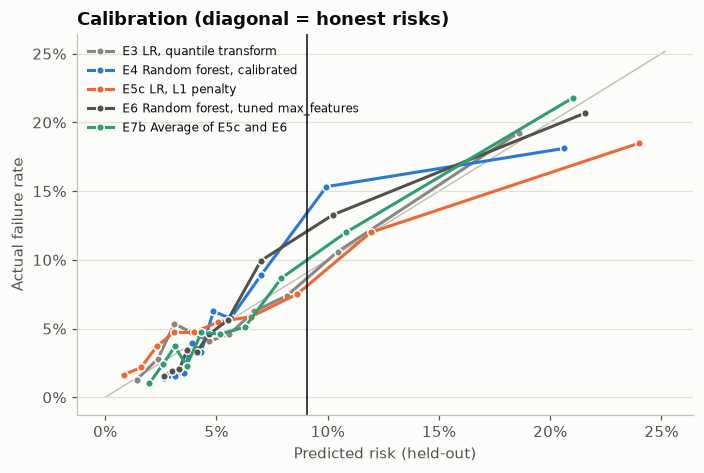

In [24]:
LINEAR = [e for e in board.index if e in ("E2", "E3", "E5a", "E5c", "E8a") or e.startswith("E8-W")]
TREES = [e for e in board.index if e in ("E4", "E5b", "E6", "E8b", "E9")]
top_linear, top_tree = board.loc[LINEAR, "Cost / wafer"].idxmin(), board.loc[TREES, "Cost / wafer"].idxmin()
SHOW = list(dict.fromkeys(["E3", "E4", top_linear, top_tree, champion]))
print(f"Best linear experiment: {top_linear} | best tree experiment: {top_tree} | champion: {champion}")

y_all = np.tile(y, N_REPEATS)                  # every wafer once per repeat
rows = {}
for e in board.index:
    r = np.clip(risk[e].ravel(), 1e-6, 1 - 1e-6)
    rows[e] = {"name": board.loc[e, "name"], "held-out log-loss": log_loss(y_all, r), "Brier": brier_score_loss(y_all, r),
               "mean risk": r.mean()}
display(pd.DataFrame(rows).T.astype({"held-out log-loss": float, "Brier": float, "mean risk": float}).round(4))
print(f"Actual failure rate: {y.mean():.4f}")

palette = [MUTED, BLUE, ORANGE, INK_2, "#2f9e6f"]
fig, ax = plt.subplots(figsize=(6.5, 4.4))
for e, color in zip(SHOW, palette):
    frac_fail, mean_risk = calibration_curve(y_all, risk[e].ravel(), n_bins=10, strategy="quantile")
    ax.plot(mean_risk, frac_fail, "o-", color=color, markersize=5, markeredgecolor=SURFACE, label=f"{e} {board.loc[e, 'name']}")
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], color=AXIS, linewidth=1, zorder=0)
ax.axvline(THRESHOLD, color=INK, linewidth=1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Predicted risk (held-out)")
ax.set_ylabel("Actual failure rate")
ax.set_title("Calibration (diagonal = honest risks)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### 7.2 What each experiment chose in its inner tuning
How often each setting won across the 25 outer folds. A setting that always sits at the edge of its grid suggests the grid should be widened.

E2 LR, standardized: C {'3e-03': 17, '1e-03': 8}
E3 LR, quantile transform: C {'3e-03': 23, '1e-03': 2}
E4 Random forest, calibrated: leaf {'10': 13, '30': 9, '3': 2, '1': 1}
E5a LR, top-k sensors: k {'442': 8, '20': 7, '40': 4, '10': 3, '80': 3} | C {'1e-02': 11, '3e-03': 9, '3e-02': 5}
E5c LR, L1 penalty: C {'1e-01': 25} | k {'72': 4, '78': 3, '73': 2, '77': 2, '69': 2, '68': 2, '79': 2, '76': 1, '81': 1, '74': 1, '70': 1, '71': 1, '64': 1, '75': 1, '65': 1}
E5b Random forest, top-k sensors: k {'40': 16, '15': 9} | leaf {'30': 24, '10': 1}
E6 Random forest, tuned max_features: max_features {'0.3': 13, '0.1': 6, 'sqrt': 6} | leaf {'10': 17, '30': 8}
E8a LR, quantile, detrended (W=200): C {'3e-03': 16, '1e-03': 9}
E8b Random forest, detrended (W=200): leaf {'10': 13, '30': 9, '3': 3}
E8-W100 LR, quantile, detrended (W=100): C {'1e-03': 15, '3e-03': 8, '3e-04': 2}
E8-W400 LR, quantile, detrended (W=400): C {'3e-03': 19, '1e-03': 6}
E9 Gradient boosting, calibrated: depth {'3': 13, '2': 

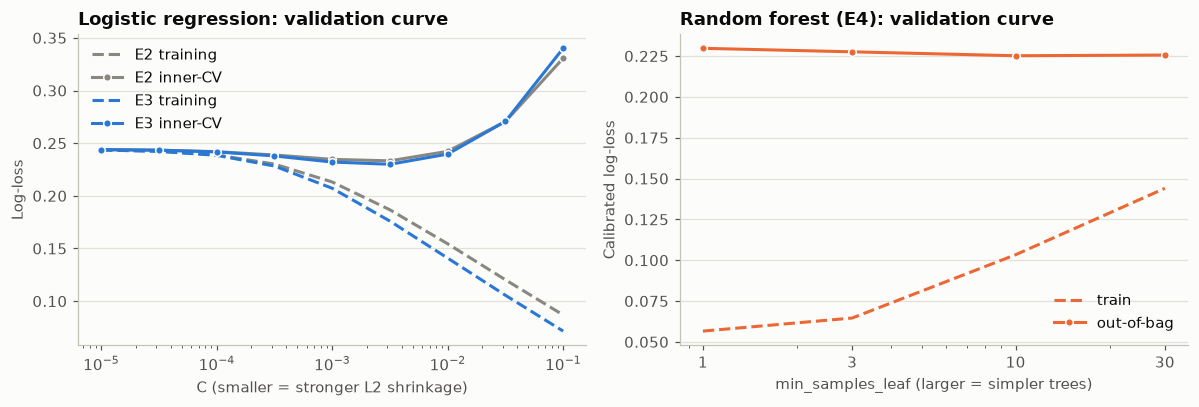

In [25]:
def fmt(v):
    return f"{v:.0e}" if isinstance(v, (float, np.floating)) else str(v)


SCALARS = {"C", "k", "leaf", "max_features", "depth"}
for e in board.index:
    diags = fold_diag.get(e) or []
    keys = [k for k in (diags[0] if diags else {}) if k in SCALARS]
    if keys:
        print(f"{e} {board.loc[e, 'name']}: " + " | ".join(
            f"{k} " + str(pd.Series([fmt(f[k]) for f in diags]).value_counts().to_dict()) for k in keys))

fig, (axb, axc) = plt.subplots(1, 2, figsize=(11, 3.8))
for key, color in (("E2", MUTED), ("E3", BLUE)):
    train_curve = np.mean([f["curve"][0] for f in fold_diag[key]], axis=0)
    valid_curve = np.mean([f["curve"][1] for f in fold_diag[key]], axis=0)
    axb.plot(C_GRID, train_curve, "--", color=color, label=f"{key} training")
    axb.plot(C_GRID, valid_curve, "o-", color=color, markersize=5, markeredgecolor=SURFACE, label=f"{key} inner-CV")
axb.set_xscale("log")
axb.set_xlabel("C (smaller = stronger L2 shrinkage)")
axb.set_ylabel("Log-loss")
axb.set_title("Logistic regression: validation curve")
axb.legend()
for part, style in (("train", "--"), ("out-of-bag", "o-")):
    values = [np.mean([f["curve"][l][part] for f in fold_diag["E4"]]) for l in LEAF_SIZES]
    axc.plot(LEAF_SIZES, values, style, color=ORANGE, markersize=5, markeredgecolor=SURFACE, label=part)
axc.set_xscale("log")
axc.set_xticks(LEAF_SIZES, [str(l) for l in LEAF_SIZES])
axc.set_xlabel("min_samples_leaf (larger = simpler trees)")
axc.set_ylabel("Calibrated log-loss")
axc.set_title("Random forest (E4): validation curve")
axc.legend()
plt.tight_layout()
plt.show()

### 7.3 Confusion matrices and the threshold
Counts are for all 1,567 wafers, each scored once by a model that never saw it, averaged over the 5 repeats. The cost curves show cost per wafer at every threshold; the threshold used everywhere else comes from the cost ratio, not from this chart.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


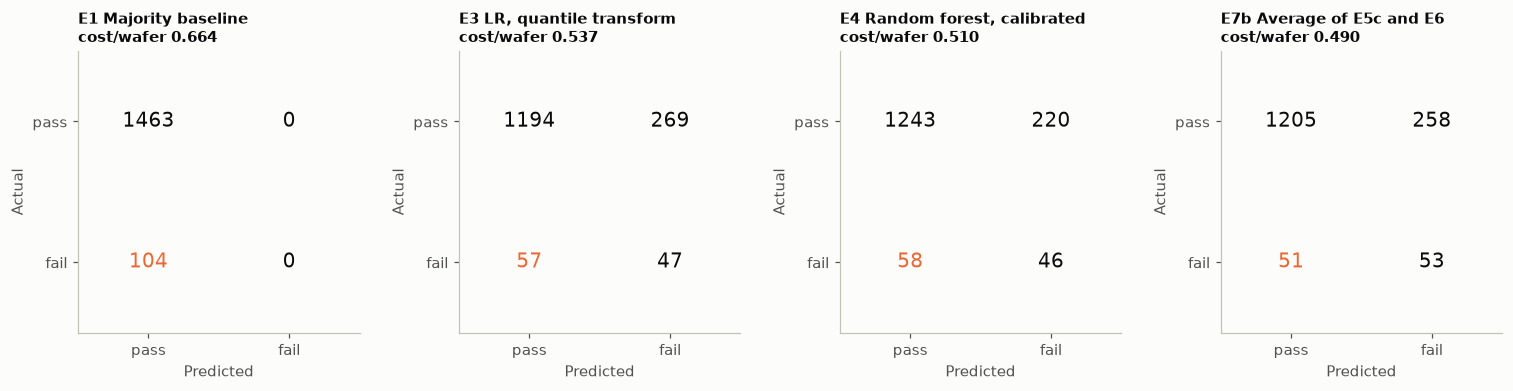

Orange: missed failures, the expensive error.


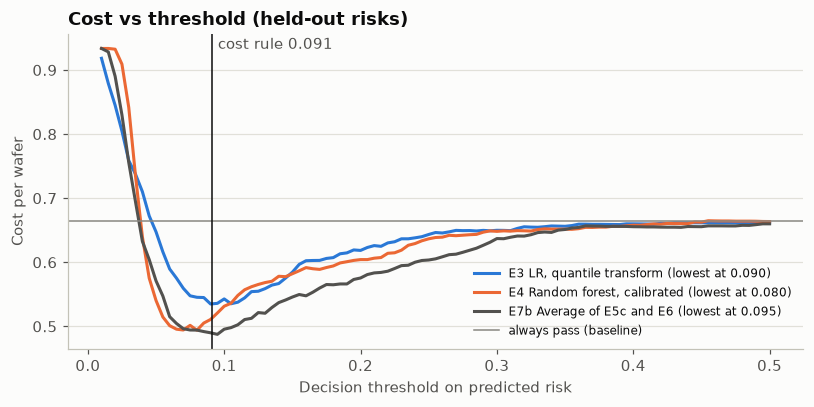

In [26]:
def pooled_confusion(key, threshold):
    """Average confusion matrix over the repeats; each repeat scores every wafer once."""
    return sum(confusion_matrix(y, (risk[key][r] >= threshold).astype(int), labels=[0, 1])
               for r in range(N_REPEATS)) / N_REPEATS


def draw_confusion(ax, cm, title):
    ax.imshow(cm, cmap=ListedColormap([SURFACE]), vmin=0, vmax=1)
    for (row, col), value in np.ndenumerate(cm):
        ax.text(col, row, f"{value:.0f}", ha="center", va="center", fontsize=13,
                color=ORANGE if (row, col) == (1, 0) else INK)
    ax.set_xticks([0, 1], ["pass", "fail"])
    ax.set_yticks([0, 1], ["pass", "fail"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title, fontsize=10)
    ax.grid(False)


def cost_of(cm):
    return (COST_FN * cm[1, 0] + COST_FP * cm[0, 1]) / cm.sum()


CM_IDS = list(dict.fromkeys(["E1", "E3", "E4", champion]))
fig, axes = plt.subplots(1, len(CM_IDS), figsize=(3.5 * len(CM_IDS), 3.4))
for ax, e in zip(np.atleast_1d(axes), CM_IDS):
    cm = pooled_confusion(e, THRESHOLD)
    draw_confusion(ax, cm, f"{e} {board.loc[e, 'name']}\ncost/wafer {cost_of(cm):.3f}")
plt.tight_layout()
plt.show()
print("Orange: missed failures, the expensive error.")

thresholds = np.round(np.arange(0.01, 0.5001, 0.005), 3)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for e, color in zip([i for i in CM_IDS if i != "E1"], palette[1:]):
    curve_cost = [cost_of(pooled_confusion(e, t)) for t in thresholds]
    ax.plot(thresholds, curve_cost, color=color, label=f"{e} {board.loc[e, 'name']} (lowest at {thresholds[int(np.argmin(curve_cost))]:.3f})")
ax.axhline(COST_FN * y.mean(), color=MUTED, linewidth=1, label="always pass (baseline)")
ax.axvline(THRESHOLD, color=INK, linewidth=1)
ax.annotate(f"cost rule {THRESHOLD:.3f}", (THRESHOLD, ax.get_ylim()[1]), xytext=(4, -2), textcoords="offset points",
            va="top", color=INK_2)
ax.set_xlabel("Decision threshold on predicted risk")
ax.set_ylabel("Cost per wafer")
ax.set_title("Cost vs threshold (held-out risks)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### 7.4 Which sensors do the models rely on?
- **Logistic regression (E3):** the coefficients, averaged over the 25 fold models. On the quantile scale every sensor has the same spread, so coefficient sizes are comparable.
- **Random forest (E4):** impurity importance, averaged over the 25 fold models. It is computed on training wafers and split between near-copies, so read it as "what the forest leans on", not proof of a sensor's effect.
- **Tuned forest (E6):** the same importance, to see whether the larger `max_features` changes what the forest leans on.

Sensors in both E3's and E4's top 15: 7 (sensor_60, sensor_104, sensor_511, sensor_478, sensor_22, sensor_206, sensor_342)
Sensors in both E4's and E6's top 15: 11


,LR coefficient (mean),LR in top 15 (of 25 folds),RF importance (mean),RF in top 15 (of 25 folds),E6 importance (mean),single-sensor AUC (3.5),Spearman with time
sensor_60,0.0791,25,0.0315,25,0.0539,0.6924,-0.4421
sensor_489,-0.0634,25,0.0021,0,0.0026,0.5547,-0.0454
sensor_130,0.0596,24,0.0033,0,0.0030,0.6192,-0.3103
sensor_34,0.0572,23,0.0034,1,0.0031,0.6106,-0.1482
sensor_104,0.0554,24,0.0121,24,0.0132,0.6682,-0.5236
sensor_486,-0.0539,19,0.0017,0,0.0014,0.5342,-0.0367
sensor_511,0.0523,23,0.0094,14,0.0097,0.6361,-0.4154
sensor_478,0.0503,24,0.0087,15,0.0128,0.6214,-0.2187
sensor_22,0.0496,17,0.0079,13,0.0090,0.6025,0.2010
sensor_206,0.0490,22,0.0114,21,0.0116,0.6193,-0.2107


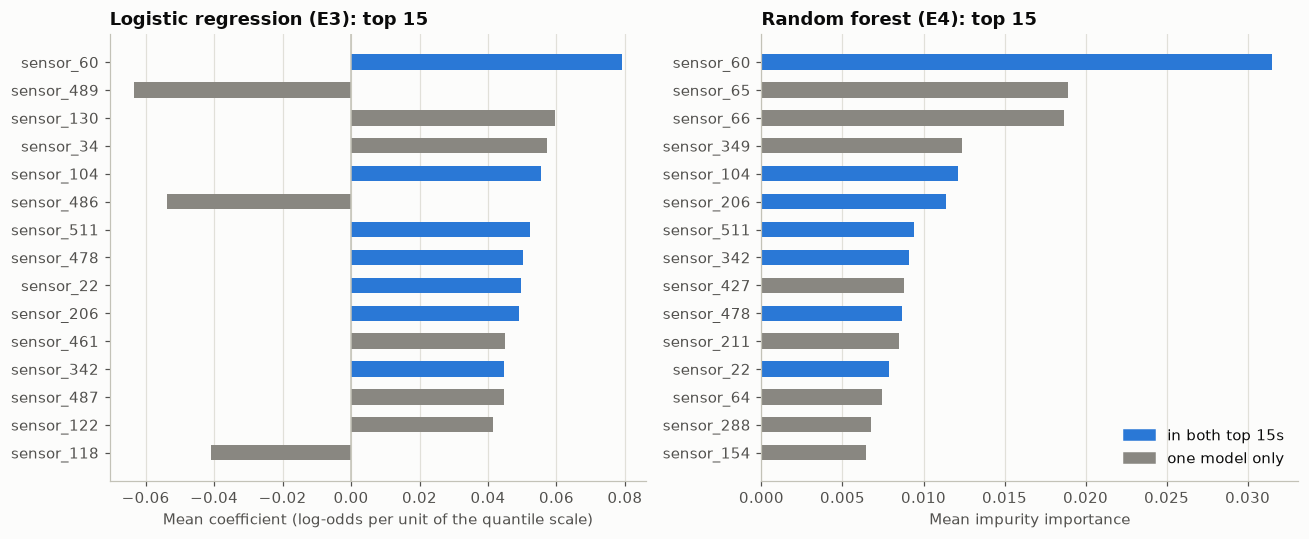

In [27]:
coef = pd.concat([f["coef"] for f in fold_diag["E3"]], axis=1)
imp = pd.concat([f["importance"] for f in fold_diag["E4"]], axis=1)
imp6 = pd.concat([f["importance"] for f in fold_diag["E6"]], axis=1)
lr_top = coef.mean(axis=1).abs().nlargest(15).index
rf_top = imp.mean(axis=1).nlargest(15).index
rf6_top = imp6.mean(axis=1).nlargest(15).index
shared = lr_top.intersection(rf_top)
print(f"Sensors in both E3's and E4's top 15: {len(shared)} ({', '.join(shared) if len(shared) else 'none'})")
print(f"Sensors in both E4's and E6's top 15: {len(rf_top.intersection(rf6_top))}")

time_rank = pd.Series(np.arange(len(y)), index=X.index)
union = lr_top.union(rf_top, sort=False)
importance_table = pd.DataFrame({
    "LR coefficient (mean)": coef.mean(axis=1)[union],
    "LR in top 15 (of 25 folds)": (coef.abs().rank(ascending=False) <= 15).sum(axis=1)[union],
    "RF importance (mean)": imp.mean(axis=1)[union],
    "RF in top 15 (of 25 folds)": (imp.rank(ascending=False) <= 15).sum(axis=1)[union],
    "E6 importance (mean)": imp6.mean(axis=1)[union],
    "single-sensor AUC (3.5)": auc_real.reindex(union),
    "Spearman with time": [X[s].corr(time_rank, method="spearman") for s in union],
})
display(importance_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, values, title, xlabel in ((axes[0], coef.mean(axis=1)[lr_top][::-1], "Logistic regression (E3): top 15",
                                   "Mean coefficient (log-odds per unit of the quantile scale)"),
                                  (axes[1], imp.mean(axis=1)[rf_top][::-1], "Random forest (E4): top 15",
                                   "Mean impurity importance")):
    ax.barh(values.index, values.to_numpy(), height=0.55,
            color=[BLUE if s in shared else MUTED for s in values.index])
    ax.axvline(0, color=AXIS, linewidth=1)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
axes[1].legend(handles=[Patch(color=BLUE, label="in both top 15s"), Patch(color=MUTED, label="one model only")],
               loc="lower right")
plt.tight_layout()
plt.show()

**Reading.** Seven sensors are in both E3's and E4's top 15 (sensor_60, 104, 511, 478, 22, 206, 342), and they are the strongest single sensors from 3.5. Several of them drift with time (Spearman -0.44 for sensor_60, -0.52 for sensor_104, -0.42 for sensor_511), so part of what both models use is *when* a wafer was made. E8 shows that removing that component costs accuracy rather than helping. E6's top 15 overlaps E4's in 11 sensors, so the larger `max_features` changes the weights more than it changes which sensors matter.

### 7.5 Which failures get caught, and where the models disagree
Uses each wafer's held-out risk averaged over the 5 repeats, so every wafer is judged by models that never saw it. A is the best linear experiment and B the best tree experiment from 7.1.

In [28]:
A_ID, B_ID = top_linear, top_tree
avg = {"A": risk[A_ID].mean(axis=0), "B": risk[B_ID].mean(axis=0)}
flag = {m: avg[m] >= THRESHOLD for m in avg}
jul_aug = timestamp.dt.month.isin([7, 8]).to_numpy()            # the high-failure period in 3.1
print(f"A = {A_ID} ({board.loc[A_ID, 'name']}) | B = {B_ID} ({board.loc[B_ID, 'name']})")

wafers = pd.DataFrame({
    "date": timestamp.dt.strftime("%d %b"),
    "actual": np.where(y == 1, "fail", "pass"),
    "A risk": avg["A"], "B risk": avg["B"],
    "missing share": X.isna().mean(axis=1).to_numpy(),
    "readings beyond 3 SD": (z.abs() > EXTREME_SD).sum(axis=1).to_numpy(),     # z from 3.3, description only
    "Jul-Aug": jul_aug,
})

rows = []
for m in ("A", "B"):
    outcome = np.select([(y == 1) & flag[m], (y == 1) & ~flag[m], (y == 0) & flag[m]],
                        ["caught failure", "missed failure", "false alarm"], default="correct pass")
    for o in ("caught failure", "missed failure", "false alarm", "correct pass"):
        sel = wafers[outcome == o]
        rows.append({"model": m, "outcome": o, "wafers": len(sel), "mean risk": sel[f"{m} risk"].mean(),
                     "missing share": sel["missing share"].mean(),
                     "readings beyond 3 SD": sel["readings beyond 3 SD"].mean(), "share from Jul-Aug": sel["Jul-Aug"].mean()})
display(pd.DataFrame(rows).set_index(["model", "outcome"]).round(3))

agree = pd.crosstab(pd.Series(np.where(flag["A"], "A flags", "A passes"), name="linear (A)"),
                    pd.Series(np.where(flag["B"], "B flags", "B passes"), name="tree (B)"), values=y, aggfunc="sum")
print("Failures by which model flags them (risks averaged over repeats):")
display(agree)

A = E5c (LR, L1 penalty) | B = E6 (Random forest, tuned max_features)


wafers  mean risk  missing share  readings beyond 3 SD  share from Jul-Aug
model outcome                                                                                   
A     caught failure      56      0.197          0.010                 7.571               0.714
      missed failure      48      0.047          0.011                 3.250               0.521
      false alarm        303      0.156          0.012                 5.076               0.690
      correct pass      1160      0.040          0.012                 3.409               0.297
B     caught failure      54      0.173          0.011                 7.537               0.852
      missed failure      50      0.055          0.010                 3.460               0.380
      false alarm        228      0.160          0.012                 6.746               0.860
      correct pass      1235      0.044          0.012                 3.202               0.289

Failures by which model flags them (risks averaged over repeats):


tree (B),B flags,B passes
linear (A),,
A flags,41,15
A passes,13,35


### 7.6 Selected cases
Eight wafers: confident misses by both models, failures only one model caught, and confident false alarms by both. "Most unusual top sensors" lists the wafer's readings furthest from normal (in SD, from 3.3) among the sensors either model relies on most.

In [29]:
top_sensors = list(union)


def unusual(i, k=3):
    zi = z.loc[i, top_sensors]
    return ", ".join(f"{s.replace('sensor_', 's')} {zi[s]:+.1f}" for s in zi.abs().nlargest(k).index)


def pick(mask, order_by, k, largest):
    idx = np.where(mask)[0]
    order = np.argsort(order_by[idx])
    return idx[order[::-1][:k]] if largest else idx[order[:k]]


max_risk, min_risk = np.maximum(avg["A"], avg["B"]), np.minimum(avg["A"], avg["B"])
fail, ok = y == 1, y == 0
picks = {"missed by both": pick(fail & ~flag["A"] & ~flag["B"], max_risk, 2, largest=False),
         "caught by B only": pick(fail & flag["B"] & ~flag["A"], avg["B"], 2, largest=True),
         "caught by A only": pick(fail & flag["A"] & ~flag["B"], avg["A"], 2, largest=True),
         "false alarm by both": pick(ok & flag["A"] & flag["B"], min_risk, 2, largest=True)}
cases = pd.DataFrame([{"wafer": i, "case": kind, **wafers.loc[i, ["date", "actual", "A risk", "B risk",
                                                                   "missing share", "readings beyond 3 SD"]].to_dict(),
                       "most unusual top sensors (SD)": unusual(i)}
                      for kind, idx in picks.items() for i in idx]).set_index("wafer")
display(cases.round({"A risk": 3, "B risk": 3, "missing share": 3}))

,case,date,actual,A risk,B risk,missing share,readings beyond 3 SD,most unusual top sensors (SD)
wafer,,,,,,,,
1211,missed by both,01 Oct,fail,0.030,0.030,0.018,5,"s489 -1.4, s461 -1.2, s130 -1.1"
795,missed by both,11 Sep,fail,0.030,0.031,0.000,1,"s487 +1.5, s489 -0.8, s511 -0.5"
368,caught by B only,21 Aug,fail,0.091,0.164,0.000,5,"s60 +2.7, s211 +2.1, s487 +2.1"
448,caught by B only,24 Aug,fail,0.083,0.151,0.000,2,"s65 +3.5, s66 +2.6, s349 +1.1"
1254,caught by A only,02 Oct,fail,0.223,0.075,0.000,3,"s349 +1.7, s122 +1.5, s486 +1.5"
1364,caught by A only,06 Oct,fail,0.219,0.053,0.000,6,"s130 +1.6, s489 -1.4, s487 +1.4"
275,false alarm by both,18 Aug,pass,0.469,0.556,0.018,43,"s342 +16.5, s206 +15.4, s478 +13.8"
457,false alarm by both,27 Aug,pass,0.486,0.368,0.027,42,"s478 +27.9, s206 +27.0, s342 +25.9"


**Reading.**
- **Who catches what.** Of the 104 failures, 41 are flagged by both models, 15 only by the linear model, 13 only by the forest, and 35 by neither. So 28 failures are caught by exactly one model, which is why averaging (E7) works.
- **Caught failures look extreme and early.** Caught failures have about 7.5 readings beyond 3 SD per wafer vs about 3.3 for missed ones, and 71–85% of them are from July–August vs 38–52% of the missed ones. The models mostly detect the early, high-failure-rate period and wafers with unusual readings.
- **False alarms look the same way:** 5–7 extreme readings and 69–86% from July–August. Wafers 275 and 457 are passes with readings 14–28 SD from normal.
- **Missed failures look ordinary.** Wafers 795 and 1211 have near-normal readings on all the top sensors (largest deviation 1.5 SD), so for these the sensors may simply not show the fault.

The written error-analysis table the assignment asks for is yours to complete from the cases above.

## 8. Experiment log
Hypotheses and the decision rule were written before running. The table below is filled in by the code from the scoreboard.

**Decision rule, set in advance:** a change is kept if it lowers mean cost per wafer *and* lowers it in at least 15 of 25 folds versus its parent. It is rejected if it raises cost, and investigated further if ROC-AUC and cost move in different directions.

In [30]:
HYPOTHESIS = {
    "E1": "Sets the floor: balanced accuracy 0.500, recall 0, cost about 0.66 per wafer",
    "E2": "The sensors carry enough signal to beat the baseline, but extreme readings (up to 40 SD) make the risks overconfident",
    "E3": "Bounding extreme readings and removing skew gives honest risks, so the same threshold catches more failures at lower cost",
    "E4": "Trees ignore scale and outliers and can combine sensors; if failures depend on combinations, the forest beats E3",
    "E5a": "Dropping the ~430 noise sensors helps the linear model",
    "E5b": "Dropping the noise sensors lets the forest's splits find the useful ones",
    "E5c": "An L1 penalty picks a few sensors from groups of near-copies and generalises better than L2",
    "E6": "Letting each split see more sensors improves the forest's ranking",
    "E7a": "Linear and tree models make different errors, so their average beats both",
    "E7b": "Same, with the best variant of each family (optimistic: chosen on the same folds)",
    "E8a": "Removing sensor drift improves the late-wafer result of the linear model",
    "E8b": "Removing sensor drift fixes the forest's collapse on late wafers",
    "E9": "Shallow boosted trees capture sparse interactions better than a forest",
}
log = board[["name", "Cost / wafer", "ROC-AUC", "parent", "Folds cheaper than parent", "Late cost", "Late ROC-AUC"]].copy()
log["parent late cost"] = [board["Late cost"].get(p, np.nan) if p else np.nan for p in log["parent"]]
log["verdict"] = board.apply(verdict, axis=1)
log["late vs parent"] = np.where(log["parent"] == "", "", np.where(log["Late cost"] < log["parent late cost"], "better", "worse"))
log.insert(1, "hypothesis", [HYPOTHESIS.get(e, "Sensitivity check of the drift window") for e in log.index])
log = log.drop(columns="parent late cost")
pd.set_option("display.max_colwidth", 90)
display(log.style.format({"Cost / wafer": "{:.3f}", "ROC-AUC": "{:.3f}", "Late cost": "{:.3f}", "Late ROC-AUC": "{:.3f}",
                          "Folds cheaper than parent": "{:.0f}"}, na_rep="").set_properties(subset=["hypothesis"], **{"text-align": "left"}))
log.to_csv(RESULTS_DIR / "experiment_log.csv")

,name,hypothesis,Cost / wafer,ROC-AUC,parent,Folds cheaper than parent,Late cost,Late ROC-AUC,verdict,late vs parent
E1,Majority baseline,"Sets the floor: balanced accuracy 0.500, recall 0, cost about 0.66 per wafer",0.664,0.500,,,0.543,0.500,,
E2,"LR, standardized","The sensors carry enough signal to beat the baseline, but extreme readings (up to 40 SD) make the risks overconfident",0.568,0.687,E1,25,0.508,0.695,keep,better
E3,"LR, quantile transform","Bounding extreme readings and removing skew gives honest risks, so the same threshold catches more failures at lower cost",0.537,0.695,E2,17,0.482,0.675,keep,better
E4,"Random forest, calibrated","Trees ignore scale and outliers and can combine sensors; if failures depend on combinations, the forest beats E3",0.510,0.742,E3,18,0.588,0.549,keep,worse
E5a,"LR, top-k sensors",Dropping the ~430 noise sensors helps the linear model,0.541,0.689,E3,6,0.569,0.569,reject,worse
E5c,"LR, L1 penalty",An L1 penalty picks a few sensors from groups of near-copies and generalises better than L2,0.530,0.704,E3,12,0.562,0.643,no clear gain,worse
E5b,"Random forest, top-k sensors",Dropping the noise sensors lets the forest's splits find the useful ones,0.511,0.736,E4,11,0.540,0.666,reject,better
E6,"Random forest, tuned max_features",Letting each split see more sensors improves the forest's ranking,0.503,0.748,E4,9,0.556,0.539,no clear gain,better
E7a,Average of E3 and E4,"Linear and tree models make different errors, so their average beats both",0.511,0.735,E4,12,0.470,0.643,reject,better
E7b,Average of E5c and E6,"Same, with the best variant of each family (optimistic: chosen on the same folds)",0.490,0.739,E4,16,0.530,0.621,keep,better


**Summary of the log.** Of the fourteen experiments run after the baseline (counting the two window checks), only the starting models (E2, E3, E4) and E7b pass the pre-set rule. E7b's gain is within noise, and E5, E6 and E7a, though not rejected, do not clear it either. Detrending and boosting are rejected. The most useful additions were the ensemble (for the late wafers) and the tuned forest and L1 penalty (for ranking), each by a small amount.

## 9. Leakage checklist

| Checklist item | Yes / No / N/A | Explanation |
|---|---|---|
| Did I split the data before fitting preprocessing such as scaling, encoding, feature selection or PCA? | Yes, with documented label-free exceptions | Imputation, standardizing or the quantile transform, **sensor selection (E5)**, C, k, the leaf size, `max_features`, tree depth and every calibration step are fitted on each outer training fold only. Inside E5a the selector is part of the inner-CV pipeline, so it is refitted on each inner training part. **Exceptions, all label-free:** (1) constant and mostly-missing sensors were dropped once on all wafers (3.2), and the clear gap between 17% and 46% missing means every fold would drop the same sensors; (2) within a training fold, the logistic regressions' inner CV shares that fold's medians and quantiles; (3) **E8's rolling-median detrending** uses only earlier sensor readings and no labels, but a training wafer's baseline can include readings of test-fold wafers that came before it. A deployed system also has the earlier readings, so this matches deployment. None touches the outer test labels |
| Are duplicate or near-duplicate records present across train/test? | No | No duplicate wafers (3.2). Many sensors are near-copies of each other, but that is redundancy between features, not repeated rows |
| Does any feature contain future information unavailable at prediction time? | No | Features are in-process sensor readings; the timestamp is not a feature. E8's baseline looks only backwards (`shift(1)`). Random CV does train on later wafers to predict earlier ones, which the time-ordered check addresses |
| Is the target indirectly encoded in one or more features? | No evidence | No single sensor exceeds AUC 0.69; a leaked target would separate the classes almost perfectly |
| For time-based data, did I preserve chronological order when appropriate? | Partly | The main estimate uses random stratified CV. The time-ordered check preserves order for every experiment. Inside it, the inner CV and out-of-bag predictions used for tuning are still a random mix of the training period |
| Did I avoid repeatedly tuning decisions on the final test set? | Mostly | The threshold comes from the cost ratio. All hyperparameters are tuned inside training folds. But the 25 outer folds were reused to compare nine experiments, so the best of them is mildly optimistic; **E7b** is chosen on those folds explicitly; and the champion rule uses the late-wafer cost as a guard. The late wafers were never used to fit or tune any model. E8's window (W = 200) was fixed before running; the other windows are reported as a sensitivity check, not selected from |
| For document-based projects, could related chunks appear in both sets? | N/A | Tabular data |
| Did I document any unresolved leakage concern? | Yes | (1) Time drift: random CV can overstate fixed-threshold performance, and the late check has only 17 failures. (2) Sensor dropping on all wafers, noted above. (3) Only 104 failures, so fold-to-fold spread is large (cost sd about 0.06) and small differences between experiments are within noise. (4) Selection among experiments on shared folds (above) |

## 10. Conclusions and next steps

**What the experiments show**
- **Both starting models beat the majority baseline** (cost 0.537 and 0.510 vs 0.664, in 24–25 of 25 folds), and the quantile transform helps the linear model (E2 → E3: 0.568 → 0.537, 17 of 25 folds).
- **Pushing the models further gives small gains at best.** The best CV cost reached is 0.490 (E7b, selected on the same folds) vs 0.510 for the starting forest; the best ROC-AUC is 0.748 (E6). All of these differences are within fold-to-fold noise. The limit seems to be the data (104 failures, weak sparse signal), not the model class.
- **Feature selection did not help the logistic regression** (E5a). An L1 penalty (E5c) and a forest on the top sensors (E5b) are roughly equal to their parents on cost, but E5b holds up much better on the late wafers.
- **A forest that sees more sensors per split (E6)** ranks slightly better and has the best single-model log-loss.
- **Averaging a linear model with a forest (E7)** is the most useful single idea: it keeps the CV performance and fixes much of the forest's weakness on the late wafers (late ROC-AUC 0.549 → 0.643, late cost 0.588 → 0.470 for E7a).
- **Removing sensor drift (E8) backfired,** and shallow boosted trees (E9) underperformed the forest.
- **Calibration and the cost threshold matter more than the model choice.** At threshold 0.5, every model flags almost nothing (flag rate at most 0.6%) and costs about the same as always passing (0.66). With the 1/11 threshold on calibrated risks, the same models cut cost by 19–26%. The forest's raw vote share (cost 0.498) is not a reliable probability, which is why it is calibrated. SMOTE was not used for the same reason: training on a 50/50 resample inflates every predicted risk and breaks the cost threshold.

**Recommended model.** The pre-set rule picks **E7b** (average of the L1 logistic regression and the tuned forest). Because it was selected on the same folds, a more defensible choice is **E7a** (average of E3 and E4), which was fixed in advance, performs like the best single model in CV and is the best on the late wafers.

**Limitations.** About 21 failures per outer fold and 17 in the late period; the 10:1 cost ratio is assumed, not measured; nine experiments were compared on the same 25 folds, so the best-looking ones are mildly optimistic; random CV mixes periods while production would not.

**Next steps.** Evaluate with time-ordered splits only (rolling-origin) and tune the ensemble weights there; recalibrate on recent wafers; add bootstrap confidence intervals for the cost differences; try an ensemble of the more diverse members (L1 logistic regression, forest, boosted trees) rather than only two; collect more failures, since the data volume appears to be the binding constraint.

### Team capstone connection
**✍** One paragraph on at least two of: the kind of baseline the capstone needs; a metric or evaluation issue that carries over (imbalance, costs, calibration); a leakage risk (time order, preprocessing outside CV); an error-analysis strategy that transfers (for example, comparing where two models disagree); what this taught you about feasibility.